# 03 Day Time Series LSTM Models with Better Evaluation
In this notebook, I'll perform similar tests to my previous notebook, but with improved evaluation. Previously, I used the test day as validation data, and I used both accuracy and precision on the entire set of test days. Now, I plan to evaluate each individual test day (and shrinking my training set to give me more test days to evaluate), along with converting everything into functions for ease of use.

Just to list out a few things I haven't tried out in previous notebooks in this repo:
 - Sliding window vs expanding window training
 - PCA, but with the proper data

## Imports

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import heatmap
import dask
import dask.dataframe as dd
from dask import delayed
from pyarrow.parquet import ParquetFile
import pyarrow as pa
from tqdm import tqdm
import pydot
from IPython.display import display

import tulipy as ti

import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.decomposition import KernelPCA
from sklearn.decomposition import IncrementalPCA

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Concatenate, LSTM, Dropout, Dense
from tensorflow.keras import initializers
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import register_keras_serializable
from tensorflow.keras.utils import plot_model
from tensorflow.keras.optimizers import SGD
import keras_tuner as kt
from keras_tuner import HyperParameters

import os
import sys
import warnings

## Data loading and continued feature engineering for LSTM model
I will condense this process all into one section, and the reasoning for doing each of the steps can be explained in the previous notebook.

Loading in the data:

In [2]:
# Loading in feature-engineered data from my SSD
FE_data_path = '/Volumes/T7/Data_For_ML_Modeling/Filtered_Cleaned_FE_Day_Data_2025_04_27.parquet'
data = pd.read_parquet(FE_data_path)

data

,Datetime,Open,High,Low,Close,Volume,PM_High,PM_Low,PM_Volume,Ticker,...,NATR_14,SMA_20,Upper_BBand,Lower_BBand,Num_STD_from_SMA_20,Close_Chg_Amt,Prev_Pos_Neg_Vol,Prev_OBV,Sto_Osc_K_RT,Sto_Osc_D_RT
2020-10-01,2020-10-01,117.70,117.720,115.8300,116.800,92076075.0,118.1000,116.5100,1755406.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN
2020-10-02,2020-10-02,112.84,115.370,112.2200,113.020,116084401.0,117.0800,112.5600,4460967.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,-3.780,0.0,0.0,NaN,NaN
2020-10-05,2020-10-05,113.92,116.650,113.5500,116.540,84421170.0,114.7100,113.3000,1690948.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,3.520,-116084401.0,-116084401.0,NaN,NaN
2020-10-06,2020-10-06,115.68,116.120,112.2500,113.160,132805466.0,116.7900,115.2300,1358666.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,-3.380,84421170.0,-31663231.0,NaN,NaN
2020-10-07,2020-10-07,114.64,115.550,114.1300,115.050,78303638.0,114.7500,113.1340,2071097.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,1.890,-132805466.0,-164468697.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-04,2024-12-04,1.30,1.300,1.1800,1.180,3412081.0,1.3000,1.2800,18315.0,WW,...,7.785161,1.062825,1.401996,0.723654,1.398556,-0.110,1407225.0,164361463.0,85.446607,83.930629
2024-12-05,2024-12-05,1.21,1.210,1.0850,1.159,4859358.0,1.2300,1.1700,82055.0,WW,...,8.995157,1.065370,1.397785,0.732955,0.870178,-0.021,-3412081.0,160949382.0,69.074040,72.105997
2024-12-06,2024-12-06,1.15,1.370,1.1450,1.365,4244740.0,1.1799,1.1118,27760.0,WW,...,9.486626,1.069815,1.402207,0.737423,0.662382,0.206,-4859358.0,156090024.0,63.598326,62.337032
2024-12-09,2024-12-09,1.37,1.550,1.3591,1.430,6100859.0,1.3900,1.3500,17138.0,WW,...,8.458922,1.105585,1.467448,0.743722,1.516677,0.065,4244740.0,160334764.0,98.208848,85.092113


Selecting top 1000 tickers based on market cap:

In [3]:
# Getting a df of just the tickers and their respective market caps and then de-duping
df_mktcap = data[["Ticker", "Market_Cap"]].drop_duplicates()
df_mktcap = df_mktcap.sort_values(by="Market_Cap", ascending=False)

# Getting a list of the top 1000 tickers by market cap and filtering out our data for just those tickers
filtered_tickers = list(df_mktcap[:1000]["Ticker"])
df_1000 = data[data["Ticker"].isin(filtered_tickers)]

df_1000

,Datetime,Open,High,Low,Close,Volume,PM_High,PM_Low,PM_Volume,Ticker,...,NATR_14,SMA_20,Upper_BBand,Lower_BBand,Num_STD_from_SMA_20,Close_Chg_Amt,Prev_Pos_Neg_Vol,Prev_OBV,Sto_Osc_K_RT,Sto_Osc_D_RT
2020-10-01,2020-10-01,117.70,117.720,115.8300,116.80,92076075.0,118.10,116.510,1755406.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN
2020-10-02,2020-10-02,112.84,115.370,112.2200,113.02,116084401.0,117.08,112.560,4460967.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,-3.78,0.0,0.0,NaN,NaN
2020-10-05,2020-10-05,113.92,116.650,113.5500,116.54,84421170.0,114.71,113.300,1690948.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,3.52,-116084401.0,-116084401.0,NaN,NaN
2020-10-06,2020-10-06,115.68,116.120,112.2500,113.16,132805466.0,116.79,115.230,1358666.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,-3.38,84421170.0,-31663231.0,NaN,NaN
2020-10-07,2020-10-07,114.64,115.550,114.1300,115.05,78303638.0,114.75,113.134,2071097.0,AAPL,...,NaN,NaN,NaN,NaN,NaN,1.89,-132805466.0,-164468697.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-04,2024-12-04,100.77,102.420,99.5000,99.51,154408.0,101.20,101.000,330.0,AXSM,...,3.414368,96.12925,103.277705,88.980795,1.418698,-1.07,223659.0,50718836.0,92.820283,72.905800
2024-12-05,2024-12-05,98.31,99.495,97.0600,98.22,131522.0,98.31,98.310,0.0,AXSM,...,3.496232,96.41225,102.979740,89.844760,0.577922,-1.29,-154408.0,50564428.0,64.454054,69.344391
2024-12-06,2024-12-06,98.31,100.240,98.1597,99.89,216298.0,98.38,97.510,200.0,AXSM,...,3.310527,96.79375,102.818540,90.768960,0.526574,1.67,-131522.0,50432906.0,65.059459,67.855856
2024-12-09,2024-12-09,100.21,102.300,97.5900,99.63,179608.0,99.99,99.990,100.0,AXSM,...,3.118623,97.36825,102.740347,91.996153,0.976062,-0.26,216298.0,50649204.0,78.983784,73.592793


Selecting base features:

In [5]:
# Getting a copy of the data to work with so we don't ruin original
data_small = df_1000.copy()

# If Rank is less than or equal to the number of NA_days, drop the row (since there will be NaN data)
NA_days = 50  # Choosing 50 for SMA_prev_50
data_small = data_small[data_small['Rank'] > NA_days]

# Since we used PM values to calculate PM_Vol_Change, there will be some NaNs or Inf (e.g., if there just wasn't any PM trading for that
# day). That is definitely somewhat unfortunate, since we likely wouldn't want to trade those stocks, but we'll include it in our data
# anyway. Therefore, we'll set the NaN and Inf values to 0
data_small['PM_Vol_Change'] = data_small['PM_Vol_Change'].replace([np.nan, np.inf, -np.inf], 0)

# Turning on the option to display all columns
pd.set_option('display.max_columns', None)

# Confirming that there are no NA values
data_small.isna().sum().sum()

np.int64(0)

In [6]:
# Only keeping certain columns
data_small_columns_keep = ['Datetime', 'Ticker', 'PM_High_0928', 'PM_Low_0928', 'PM_Close_0928', 'PM_Volume_0928', 'PDO', 'PDH', 'PDL',
    'PDC', 'PDV', 'Avg_PM_Vol_Prev_14D', 'Gap_from_PDC', 'Gap_Binary_Threshold', 'Daily_Range_Gap_Up', 'DR_Gap_Up_Binary',
    'Daily_Range_Gap_Down', 'DR_Gap_Down_Binary', 'PM_Vol_Change', 'Industry', 'Market_Cap', 'SMA_Prev_14', 'SMA_20', 'SMA_Prev_50',
    'EMA_Prev_9', 'EMA_Prev_20', 'RSI_14', 'NATR_14', 'Upper_BBand', 'Lower_BBand', 'Num_STD_from_SMA_20', 'Prev_OBV', 'Sto_Osc_K_RT',
    'Sto_Osc_D_RT', 'Close_Open_Diff_Perc', 'Close_Open_Diff_Ternary']

data_small = data_small[data_small_columns_keep]

display(len(data_small_columns_keep))
display(data_small.describe())

36

,Datetime,PM_High_0928,PM_Low_0928,PM_Close_0928,PM_Volume_0928,PDO,PDH,PDL,PDC,PDV,Avg_PM_Vol_Prev_14D,Gap_from_PDC,Daily_Range_Gap_Up,Daily_Range_Gap_Down,PM_Vol_Change,Market_Cap,SMA_Prev_14,SMA_20,SMA_Prev_50,EMA_Prev_9,EMA_Prev_20,RSI_14,NATR_14,Upper_BBand,Lower_BBand,Num_STD_from_SMA_20,Prev_OBV,Sto_Osc_K_RT,Sto_Osc_D_RT,Close_Open_Diff_Perc,Close_Open_Diff_Ternary
count,1005000,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06
mean,2022-12-11 20:42:16.119403008,1.407914e+02,1.402512e+02,1.405109e+02,2.832291e+04,1.404596e+02,1.422217e+02,1.386674e+02,1.404678e+02,2.628114e+06,2.834053e+04,4.949761e-04,1.368367e-03,-1.281908e-03,4.220245e+00,6.165581e+10,1.401747e+02,1.400841e+02,1.393350e+02,1.402890e+02,1.400394e+02,5.201304e+01,2.539780e+00,1.496446e+02,1.305236e+02,1.258969e-01,3.152249e+07,5.356921e+01,5.339563e+01,2.140141e-02,1.011695e+00
min,2020-12-11 00:00:00,7.141000e-01,6.801000e-01,7.141000e-01,0.000000e+00,6.665000e-01,7.798000e-01,2.500000e-01,6.890000e-01,0.000000e+00,0.000000e+00,-9.798976e-01,0.000000e+00,-9.794586e-01,-1.000000e+00,5.100000e+09,8.980857e-01,9.336600e-01,8.657880e-01,8.337746e-01,9.123886e-01,0.000000e+00,2.004522e-01,1.121882e+00,-2.005427e+03,-4.238944e+00,-1.796575e+09,0.000000e+00,0.000000e+00,-5.008123e+01,0.000000e+00
25%,2021-12-10 00:00:00,4.015000e+01,3.990000e+01,4.000000e+01,0.000000e+00,4.000000e+01,4.053000e+01,3.946000e+01,4.000000e+01,2.960928e+05,7.671429e+01,-4.172989e-03,0.000000e+00,0.000000e+00,-1.000000e+00,9.007500e+09,3.998143e+01,3.999197e+01,3.982515e+01,4.000709e+01,4.000173e+01,3.980457e+01,1.740680e+00,4.274196e+01,3.710020e+01,-8.903576e-01,2.098938e+05,2.595231e+01,2.676511e+01,-9.169233e-01,0.000000e+00
50%,2022-12-09 00:00:00,7.924000e+01,7.896000e+01,7.906000e+01,1.070000e+02,7.905000e+01,8.002000e+01,7.806000e+01,7.905000e+01,7.627325e+05,7.004286e+02,4.101162e-04,0.000000e+00,0.000000e+00,-7.664332e-01,1.807500e+10,7.893727e+01,7.888050e+01,7.854135e+01,7.901137e+01,7.890252e+01,5.206271e+01,2.232338e+00,8.403175e+01,7.375689e+01,2.129316e-01,9.011696e+06,5.579184e+01,5.562944e+01,2.550695e-02,1.000000e+00
75%,2023-12-11 00:00:00,1.548600e+02,1.541700e+02,1.545000e+02,2.950000e+03,1.544600e+02,1.564100e+02,1.524900e+02,1.545000e+02,2.073546e+06,5.876661e+03,5.295919e-03,0.000000e+00,0.000000e+00,0.000000e+00,4.770000e+10,1.540329e+02,1.539302e+02,1.531502e+02,1.542655e+02,1.540490e+02,6.437475e+01,2.952197e+00,1.640878e+02,1.438936e+02,1.142133e+00,3.429412e+07,8.172635e+01,8.046239e+01,9.468831e-01,2.000000e+00
max,2024-12-10 00:00:00,9.914170e+03,9.914170e+03,9.914170e+03,1.941779e+08,9.914170e+03,9.964770e+03,9.794000e+03,9.922590e+03,1.017757e+09,2.797966e+07,8.596639e+00,8.209677e+00,0.000000e+00,9.045258e+04,2.918340e+12,9.689424e+03,9.688178e+03,9.454171e+03,9.757990e+03,9.647032e+03,1.000000e+02,1.707141e+02,1.002093e+04,9.389099e+03,4.248141e+00,4.667864e+09,1.000000e+02,1.000000e+02,2.831579e+02,2.000000e+00
std,NaN,2.846837e+02,2.841613e+02,2.844219e+02,3.907997e+05,2.842312e+02,2.876188e+02,2.808455e+02,2.842836e+02,7.645709e+06,2.165459e+05,2.118239e-02,1.593568e-02,8.358116e-03,2.520952e+02,2.030093e+11,2.828645e+02,2.824058e+02,2.790687e+02,2.833161e+02,2.820280e+02,1.700931e+01,1.439189e+00,3.008494e+02,2.660835e+02,1.207081e+00,1.751612e+08,3.088682e+01,2.913905e+01,1.919794e+00,8.410857e-01


Normalizing the data:

In [8]:
# Defining a function to normalize the prices/volume to the mean of every ticker
def normalize_to_mean_per_ticker(df, col_list):
    df_normalized = df.copy()

    # Grouping by Ticker and getting the mean values for either price or volume by ticker
    mean_vals = df_normalized.groupby('Ticker')[col_list].transform('mean').mean(axis=1)

    # Applying normalization to entire df by dividing by mean values for each ticker
    df_normalized[col_list] = df_normalized[col_list].div(mean_vals, axis=0)

    return df_normalized

Furthermore, I will normalize the columns to the **global** mean prices (by percent compared to mean price) for each ticker. For example, if the OHLC for a day is 2, 4, 1, 3, respectively, then their normalized versions would be 0.8, 1.6, 0.4, 1.2 (assuming that 2.5 was the global mean) overall. This will preserve long-term trends, and we can see how the price moves through multiple days of trading.

In [9]:
# Normalizing the following price columns to the global mean price for each ticker
price_cols_to_norm = ['PM_High_0928', 'PM_Low_0928', 'PM_Close_0928', 'PDO', 'PDH', 'PDL', 'PDC', 'SMA_Prev_14', 'SMA_20',
                      'SMA_Prev_50', 'EMA_Prev_9', 'EMA_Prev_20', 'Upper_BBand', 'Lower_BBand']
data_small = normalize_to_mean_per_ticker(data_small, price_cols_to_norm)

# Normalizing the following volume columns to the mean volume for each ticker
vol_cols_to_norm = ['PDV', 'Prev_OBV']
data_small = normalize_to_mean_per_ticker(data_small, vol_cols_to_norm)

# Normalizing the following PM volume columns to the mean PM volume for each ticker
PM_vol_cols_to_norm = ['PM_Volume_0928', 'Avg_PM_Vol_Prev_14D']
data_small = normalize_to_mean_per_ticker(data_small, PM_vol_cols_to_norm)

# Performing a log10 transform on market cap and then normalizing it to the average across all tickers
data_small['Market_Cap'] = data_small['Market_Cap'].apply(np.log10)
mkt_cap_norm_mean = data_small['Market_Cap'].mean()
data_small['Market_Cap'] = data_small['Market_Cap'] / mkt_cap_norm_mean

# Normalizing the following columns as percent (currently these are decimal changes) (except Vol_Change)
cols_to_perc = ['Gap_from_PDC', 'Daily_Range_Gap_Up', 'Daily_Range_Gap_Down']
data_small.loc[:, cols_to_perc] = data_small.loc[:, cols_to_perc] * 100

# Normalizing RSI and Stochastic Oscillators to be between 0 and 1
norm_to_0_1_cols = ['RSI_14', 'Sto_Osc_K_RT', 'Sto_Osc_D_RT']
data_small.loc[:, norm_to_0_1_cols] = data_small.loc[:, norm_to_0_1_cols] / 100

data_small.describe()

,Datetime,PM_High_0928,PM_Low_0928,PM_Close_0928,PM_Volume_0928,PDO,PDH,PDL,PDC,PDV,Avg_PM_Vol_Prev_14D,Gap_from_PDC,Daily_Range_Gap_Up,Daily_Range_Gap_Down,PM_Vol_Change,Market_Cap,SMA_Prev_14,SMA_20,SMA_Prev_50,EMA_Prev_9,EMA_Prev_20,RSI_14,NATR_14,Upper_BBand,Lower_BBand,Num_STD_from_SMA_20,Prev_OBV,Sto_Osc_K_RT,Sto_Osc_D_RT,Close_Open_Diff_Perc,Close_Open_Diff_Ternary
count,1005000,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06,1.005000e+06
mean,2022-12-11 20:42:16.119403008,1.004941e+00,9.992777e-01,1.001968e+00,1.002400e+00,1.001551e+00,1.014492e+00,9.883986e-01,1.001550e+00,3.714502e-01,9.975996e-01,4.949761e-02,1.368367e-01,-1.281908e-01,4.220245e+00,1.000000e+00,9.994362e-01,9.987800e-01,9.932101e-01,1.000261e+00,9.985751e-01,5.201304e-01,2.539780e+00,1.067952e+00,9.296082e-01,1.258969e-01,1.628550e+00,5.356921e-01,5.339563e-01,2.140141e-02,1.011695e+00
min,2020-12-11 00:00:00,1.825898e-02,1.712466e-02,1.777314e-02,0.000000e+00,1.774357e-02,2.086982e-02,1.337504e-02,1.822518e-02,-1.076030e+03,0.000000e+00,-9.798976e+01,0.000000e+00,-9.794586e+01,-1.000000e+00,9.367940e-01,2.452234e-02,2.511328e-02,2.818980e-02,2.384866e-02,2.626187e-02,0.000000e+00,2.004522e-01,2.991754e-02,-2.285838e+00,-4.238944e+00,-1.205840e+04,0.000000e+00,0.000000e+00,-5.008123e+01,0.000000e+00
25%,2021-12-10 00:00:00,8.468480e-01,8.424594e-01,8.445280e-01,0.000000e+00,8.442980e-01,8.556579e-01,8.330539e-01,8.444797e-01,1.790728e-02,1.139908e-01,-4.172989e-01,0.000000e+00,0.000000e+00,-1.000000e+00,9.606331e-01,8.448385e-01,8.452586e-01,8.453215e-01,8.452334e-01,8.463056e-01,3.980457e-01,1.740680e+00,9.017239e-01,7.834865e-01,-8.903576e-01,9.125037e-01,2.595231e-01,2.676511e-01,-9.169233e-01,0.000000e+00
50%,2022-12-09 00:00:00,9.782028e-01,9.741750e-01,9.760667e-01,4.295646e-02,9.758167e-01,9.868579e-01,9.646243e-01,9.759745e-01,5.260811e-02,3.748150e-01,4.101162e-02,0.000000e+00,0.000000e+00,-7.664332e-01,9.898223e-01,9.747213e-01,9.745256e-01,9.710056e-01,9.751970e-01,9.742674e-01,5.206271e-01,2.232338e+00,1.031503e+00,9.159943e-01,2.129316e-01,1.915977e+00,5.579184e-01,5.562944e-01,2.550695e-02,1.000000e+00
75%,2023-12-11 00:00:00,1.120376e+00,1.115218e+00,1.117681e+00,4.352856e-01,1.117353e+00,1.129781e+00,1.104418e+00,1.117219e+00,1.188400e-01,9.257809e-01,5.295919e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.030492e+00,1.113715e+00,1.112682e+00,1.104888e+00,1.114572e+00,1.111487e+00,6.437475e-01,2.952197e+00,1.181206e+00,1.048267e+00,1.142133e+00,2.902093e+00,8.172635e-01,8.046239e-01,9.468831e-01,2.000000e+00
max,2024-12-10 00:00:00,7.061103e+00,6.280767e+00,6.548334e+00,9.549454e+02,6.516145e+00,6.817912e+00,5.819703e+00,6.421592e+00,3.243786e+03,6.821038e+01,8.596639e+02,8.209677e+02,0.000000e+00,9.045258e+04,1.202903e+00,5.716735e+00,5.660247e+00,5.215130e+00,5.764834e+00,5.554490e+00,1.000000e+00,1.707141e+02,7.360601e+00,5.348269e+00,4.248141e+00,8.463608e+03,1.000000e+00,1.000000e+00,2.831579e+02,2.000000e+00
std,NaN,3.019156e-01,2.988639e-01,3.003107e-01,9.205163e+00,3.000320e-01,3.048085e-01,2.948117e-01,2.997334e-01,1.648744e+01,2.631630e+00,2.118239e+00,1.593568e+00,8.358116e-01,2.520952e+02,4.843146e-02,2.953817e-01,2.938447e-01,2.860736e-01,2.961073e-01,2.918879e-01,1.700931e-01,1.439189e+00,3.283147e-01,2.753175e-01,1.207081e+00,1.661748e+02,3.088682e-01,2.913905e-01,1.919794e+00,8.410857e-01


Label-encoding the Industry column by mapping each industry to a unique integer:

In [11]:
# Encoding the industry by getting their respective Industry IDs
le = LabelEncoder()
data_small['Industry_ID'] = le.fit_transform(data_small['Industry'])

data_small.head()

,Datetime,Ticker,PM_High_0928,PM_Low_0928,PM_Close_0928,PM_Volume_0928,PDO,PDH,PDL,PDC,PDV,Avg_PM_Vol_Prev_14D,Gap_from_PDC,Gap_Binary_Threshold,Daily_Range_Gap_Up,DR_Gap_Up_Binary,Daily_Range_Gap_Down,DR_Gap_Down_Binary,PM_Vol_Change,Industry,Market_Cap,SMA_Prev_14,SMA_20,SMA_Prev_50,EMA_Prev_9,EMA_Prev_20,RSI_14,NATR_14,Upper_BBand,Lower_BBand,Num_STD_from_SMA_20,Prev_OBV,Sto_Osc_K_RT,Sto_Osc_D_RT,Close_Open_Diff_Perc,Close_Open_Diff_Ternary,Industry_ID
2020-12-11,2020-12-11,AAPL,0.738878,0.729927,0.735874,0.785821,0.723859,0.744165,0.721816,0.740260,-1.412617,1.187205,-0.592436,False,0.000000,False,0.0,False,-0.338092,Household Durables,1.202903,0.721724,0.720908,0.706568,0.733054,0.722589,0.626036,2.180768,0.758621,0.683195,0.793704,2.371272,0.741018,0.738772,0.040836,1,33
2020-12-14,2020-12-14,AAPL,0.740500,0.733471,0.736835,1.299306,0.735574,0.737496,0.724219,0.735874,-1.473669,1.211414,0.130623,False,0.000000,False,0.0,False,0.072553,Household Durables,1.202903,0.723943,0.721929,0.707252,0.733618,0.723854,0.754498,2.064892,0.760231,0.683627,0.778366,3.844941,0.752994,0.763224,-0.676998,0,33
2020-12-15,2020-12-15,AAPL,0.747889,0.732930,0.747289,2.538753,0.736535,0.741041,0.730167,0.731549,-1.197427,1.226432,2.151597,True,0.843129,True,0.0,False,1.070033,Household Durables,1.202903,0.727328,0.722878,0.708303,0.733204,0.724587,0.741109,2.082967,0.762515,0.683241,1.231706,5.042368,0.855288,0.761144,2.780680,2,33
2020-12-16,2020-12-16,AAPL,0.773182,0.762248,0.765612,1.674937,0.747529,0.768375,0.745727,0.768315,-2.764059,1.256586,-0.351865,False,0.000000,False,0.0,False,0.332927,Household Durables,1.202903,0.732787,0.726357,0.709667,0.740227,0.728752,0.756976,2.055338,0.773332,0.679381,1.671315,2.278309,0.899038,0.861793,0.282597,1,33
2020-12-17,2020-12-17,AAPL,0.777387,0.766513,0.774383,1.293692,0.765312,0.771199,0.760325,0.767474,-1.659911,1.298824,0.900196,False,0.412869,True,0.0,False,-0.003951,Household Durables,1.202903,0.737820,0.729724,0.711420,0.745676,0.732440,0.775028,2.087224,0.780831,0.678617,1.747686,3.938220,0.960286,0.969491,-0.193949,1,33


In [12]:
# Ordering by date, and then by ticker to get the right splits for train/val/test
data_small = data_small.sort_values(by=['Datetime', 'Ticker'])
data_small.shape

(1005000, 37)

## Function to generate features and outcome variables for LSTM model
Here, I create a function to generate the X series sequences and Y outcome variables, ordered first by the date, and then by the ticker. I also use it to generate Industry_ID features to be used in embeddings layers on.

The following is the updated function used to create the respective X and Y sequences in the LSTM models:

In [14]:
# Function for creating sequences (with embeddings) for LSTM model
def create_sequences_with_embeddings(df, seq_length, group_col, target_col, drop_cols, embedding_cols):
    """
    Create LSTM sequences with both numeric features and embedding inputs.

    Parameters:
        df: DataFrame with time series data
        seq_length: length of each input sequence
        group_col: column name to group sequences by (e.g., 'Ticker')
        target_col: name of the target (label) column
        drop_cols: list of columns to drop (e.g., Datetime or Date_col, unused metrics)
        embedding_cols: list of categorical columns to embed (e.g., ['Industry_ID'])

    Returns:
        X_numeric: shape (samples, seq_length, num_numeric_features)
        X_embeddings: list of arrays, one per embedding column, each shape (samples, seq_length)
        Y: (samples,)
    """
   
    X_numeric, Y = [], []
    X_embeddings = [[] for _ in embedding_cols]
    num_tickers = df[group_col].nunique()
    
    # Group data by unique time series identifier (i.e., 'Ticker')
    grouped = df.groupby(group_col)
    
    for _, group in tqdm(grouped):
        # Sorting by Date_col and removing the 'Ticker' column and dropped columns
        group = group.sort_values(by='Datetime')
        
        # Separating out the target and embedded columns
        labels = group[target_col].values
        embed_data = [group[col].values for col in embedding_cols]

        # Dropping group_col, target_col, embedding_cols, and drop_cols to isolate numeric features
        exclude = drop_cols + [group_col, target_col] + embedding_cols
        feature_cols = group.drop(columns=exclude).columns
        feature_data = group[feature_cols].values

        # Creating sequences for this group only
        for i in range(len(group) - seq_length + 1):
            X_numeric.append(feature_data[i:i+seq_length])  # Collecting seq_length time steps of metric features
            for j, col_values in enumerate(embed_data):
                X_embeddings[j].append(col_values[i:i+seq_length])  # Collecting seq_length time steps of embedding cols
            Y.append(labels[i+seq_length-1])  # Target label is the most recent time step
    print("Creating grouped sequences complete.")
    
    # Convert to numpy arrays and the correct dtypes
    X_numeric = np.array(X_numeric).astype(np.float32)
    X_embeddings = [np.array(embed).astype(np.int32) for embed in X_embeddings]
    Y = np.array(Y).astype(np.int32)
    print("Conversion to np arrays and appropriate dtypes complete.")
    
    # Re-ordering data first by the date, and then by the ticker
    indices_by_date_then_ticker = np.arange(X_numeric.shape[0]).reshape((num_tickers, -1)).flatten('F')
    X_numeric = X_numeric[indices_by_date_then_ticker]
    X_embeddings = [x[indices_by_date_then_ticker] for x in X_embeddings]
    Y = Y[indices_by_date_then_ticker]
    print("Re-ordering complete.")
    
    return X_numeric, X_embeddings, Y

## Functions for splitting the dataset, building/compiling the model, and evaluating performance
These are all general functions that can be used with most of the LSTM models I'm planning to run.

The following function is used to constantly generate new training, validation, and test data splits. The validation split is still set to 0, but I'll still keep it here as there's no reason to remove it.

In [18]:
# Defining function to split sequence data into train, val, test splits with split size (in terms of # of days)
def train_val_test_seq_split(data_window, num_tickers, train_size, val_size, test_size):
    df = data_window.copy()

    if (df.shape[0]/num_tickers) != (train_size + val_size + test_size):
        print("Train + val + test sizes do not much number of dates")
        return None

    df_train = df[:(num_tickers * train_size)]
    df_val = df[(num_tickers * train_size):(num_tickers * (train_size + val_size))]
    df_test = df[(num_tickers * (train_size + val_size)):]

    return df_train, df_val, df_test

The following function is used to build, compile, and run my LSTM model using X_num_train, X_embed_train, and Y_train:

In [62]:
# Defining a function to create the LSTM model using the Keras functional API along with embeddings
def build_LSTM_model_func_API_embed(seq_length,
                                    num_features,  # Excluding Industry
                                    n_classes,
                                    num_industries,
                                    embedding_dim=5,
                                    LSTM_layers=1,
                                    LSTM_units=128,
                                    dropout_rate=0.3,
                                    hidden_layer_sizes=[],
                                    activation='relu',
                                    learning_rate=0.0001,
                                    optimizer='Adam',
                                    metrics=['accuracy']):

    # Resetting tf for consistent results
    tf.keras.backend.clear_session()
    np.random.seed(0)
    tf.random.set_seed(0)

    # Getting the Input features
    features_input = Input(shape=(seq_length, num_features), name='Features_Input')
    industry_input = Input(shape=(seq_length,), dtype='int32', name='Industry_Input')

    # Getting the embedding for Industry
    industry_embedded = Embedding(input_dim=num_industries, output_dim=embedding_dim, name='Industry_Embedding')(industry_input)

    # Concatenating embedded industry with features (shape: (batch, seq_length, num_features + embedding_dim))
    x = Concatenate(axis=-1, name='Feature_Concat')([features_input, industry_embedded])

    # Getting the LSTM and Dropout layers
    for i in range(LSTM_layers):
        
        LSTM_return_sequences = True
        if i + 1 == LSTM_layers:
            LSTM_return_sequences = False
        
        LSTM_layer_name = 'LSTM' + str(i)
        x = LSTM(units=LSTM_units, return_sequences=LSTM_return_sequences, name=LSTM_layer_name)(x)

        LSTM_dropout_name = 'Dropout' + str(i)
        x = Dropout(dropout_rate, name=LSTM_dropout_name)(x)

    # Adding in hidden layers and dropout layers
    for idx, hidden_layer_size in enumerate(hidden_layer_sizes):
        hidden_layer_name = 'Hidden' + str(idx)
        x = Dense(units=hidden_layer_size, activation=activation, name=hidden_layer_name)(x)
        HL_dropout_name = 'HL_Dropout' + str(idx)
        x = Dropout(dropout_rate, name=HL_dropout_name)(x)
    
    # Finishing with the output layer
    output = Dense(units=n_classes, activation='softmax', name='Output')(x)

    model = tf.keras.Model(inputs=[features_input, industry_input], outputs=output, name='LSTM_Embed')
    
    # Compiling the model
    optimizer_class = getattr(tf.keras.optimizers, optimizer)
    optimizer_instance = optimizer_class(learning_rate=learning_rate)
    model.compile(optimizer=optimizer_instance,
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                  metrics=metrics)
    
    return model

The following function is used to obtain my results across individual test days:

In [84]:
# Function for obtaining results across individual test days
def obtain_indiv_day_results(model, X_test_numeric, X_test_embedding, Y_test, num_test_days, num_tickers, pred_threshold):

    # Initializing list of confusion matrices
    conf_matrix_list = []

    # Checking to ensure that the X_test matrix has correct shape
    X_test_days = X_test_numeric.shape[0] / num_tickers
    if X_test_days != num_test_days:
        print("Number of test days x unique tickers does not match the amount of data in X_test")
        return None
    
    # Looping over the window to get individual X_test and Y_test days
    for first_ticker_idx in tqdm(range(0, X_test_numeric.shape[0], num_tickers)):
        X_num_indiv = X_test_numeric[first_ticker_idx:(first_ticker_idx + num_tickers)]
        X_embed_indiv = X_test_embedding[first_ticker_idx:(first_ticker_idx + num_tickers)]
        Y_test_indiv = Y_test[first_ticker_idx:(first_ticker_idx + num_tickers)]
        
        # Getting the test predictions and using the threshold to get the confusion matrix
        Y_pred = model.predict(x={"Features_Input": X_num_indiv, "Industry_Input": X_embed_indiv}, verbose=0)
        Y_pred_thresh = np.where(Y_pred[:, 0] > pred_threshold, 0,
                                 np.where(Y_pred[:, 2] > pred_threshold, 2, 1))

        # Getting the confusion matrix of the predictions and adding it to the conf_matrix_list
        cf_thresh = confusion_matrix(Y_test_indiv, Y_pred_thresh)
        conf_matrix_list.append(cf_thresh)

    return conf_matrix_list

The following function is used to generate metrics and evaluate my results across individual test days (for Class 0 and Class 2):

In [54]:
# Function for evaluating model performance across individual test days
warnings.filterwarnings('ignore')
def model_eval_indiv_day(conf_matrix_list):
    
    # Initializing dictionary of lists of precisions and fp for Class 0 and Class 2
    prec_fp_dict = {
        'Class 0 Precisions': [],
        'Class 2 Precisions': [],
        'Class 0 Opposite FP': [],
        'Class 2 Opposite FP': [],
        'Class 0 Neutral FP': [],
        'Class 2 Neutral FP': []
    }
   
    # Getting the precision scores and fp rates for Class 0 and Class 2 for every test day
    for test_day_num, cf_indiv in enumerate(conf_matrix_list):
    
        # Getting more granular precision metrics for classes 0 and 2
        sum_pred_0 = np.sum(cf_indiv, axis=0)[0]
        sum_pred_2 = np.sum(cf_indiv, axis=0)[2]
        pred_0_true_0 = cf_indiv[0, 0] / sum_pred_0
        pred_0_true_1 = cf_indiv[1, 0] / sum_pred_0
        pred_0_true_2 = cf_indiv[2, 0] / sum_pred_0
        pred_2_true_0 = cf_indiv[0, 2] / sum_pred_2
        pred_2_true_1 = cf_indiv[1, 2] / sum_pred_2
        pred_2_true_2 = cf_indiv[2, 2] / sum_pred_2
    
        # Adding each precision to their respective lists in the precision dictionary
        prec_fp_dict['Class 0 Precisions'].append(pred_0_true_0)
        prec_fp_dict['Class 2 Precisions'].append(pred_2_true_2)
        prec_fp_dict['Class 0 Opposite FP'].append(pred_0_true_2)
        prec_fp_dict['Class 2 Opposite FP'].append(pred_2_true_0)
        prec_fp_dict['Class 0 Neutral FP'].append(pred_0_true_1)
        prec_fp_dict['Class 2 Neutral FP'].append(pred_2_true_1)
        
    return prec_fp_dict

# LSTM Base Model (50 test days)
As mentioned previously, I'm going to lower the amount of training data I have in exchange for more test data. This will allow me to better comprehend how well my model generalizes.

## Generating X continuous series sequences, X Industry_ID features, and Y continuous labels for LSTM model, along with splitting the data
Here, I generate the X series sequences and respective Y continuous labels, ordered first by the date, and then by the ticker. I also generate the Industry_ID features to be used in embeddings layers on. Lastly, I split the data appropriately.

In [15]:
# Creating sequences for LSTM model
seq_length = 50
group_col = 'Ticker'
target_col = 'Close_Open_Diff_Ternary'
drop_cols = ['Datetime', 'Industry', 'Close_Open_Diff_Perc']
embedding_cols = ['Industry_ID']

X_data_small_num, X_data_small_embed, Y_data_small = create_sequences_with_embeddings(
    data_small, seq_length, group_col, target_col, drop_cols, embedding_cols)

100%|█████████████████████████████████████| 1000/1000 [00:00<00:00, 1229.79it/s]


Creating grouped sequences complete.
Conversion to np arrays and appropriate dtypes complete.
Re-ordering complete.


In [16]:
# Confirming shapes
print('Shape of X_data_small_num:', X_data_small_num.shape)
for idx, embed_col in enumerate(embedding_cols):
    print('Shape of col', idx+1, 'in X_data_small_embed:', X_data_small_embed[idx].shape)
print('Shape of Y_data_small:', Y_data_small.shape, '\n')

# Confirming that we should have the correct number of sequences in X_data_small_num
unique_tickers = data_small['Ticker'].nunique()
unique_dates = data_small['Datetime'].nunique()
expected_num_sequences = unique_tickers * (unique_dates - seq_length + 1)

print('Number of unique tickers in data_small:', unique_tickers)
print('Number of unique dates in data_small:', unique_dates)
print('Chosen sequence length:', seq_length)
print('Number of sequences assuming the above seq_length:', unique_dates - seq_length + 1)
print('(We need to add 1 to the end to account for either the beginning or the end. For example, if we had 12 observations with a window')
print('of 5, we would need 12 - 5 + 1 = 8 sequences, the first one being having indices from [0:5], and the last from [7:12].)\n')
print('Total number of data sequences expected:', expected_num_sequences)
print('Total number of data sequences achieved:', X_data_small_num.shape[0])

Shape of X_data_small_num: (956000, 50, 31)
Shape of col 1 in X_data_small_embed: (956000, 50)
Shape of Y_data_small: (956000,) 

Number of unique tickers in data_small: 1000
Number of unique dates in data_small: 1005
Chosen sequence length: 50
Number of sequences assuming the above seq_length: 956
(We need to add 1 to the end to account for either the beginning or the end. For example, if we had 12 observations with a window
of 5, we would need 12 - 5 + 1 = 8 sequences, the first one being having indices from [0:5], and the last from [7:12].)

Total number of data sequences expected: 956000
Total number of data sequences achieved: 956000


In [19]:
# Setting initial parameters for splits
num_sequences_per_ticker = unique_dates - seq_length + 1  # unique_dates is from above
test_size = 50
val_size = 0
train_size = num_sequences_per_ticker - test_size
X_data_small_industry = X_data_small_embed[0]

# Performing the data splits with my X_data_small_num, X_data_small_embed, and Y_data_small
X_num_train, _, X_num_test = train_val_test_seq_split(X_data_small_num, unique_tickers, train_size, val_size, test_size)
X_embed_train, _, X_embed_test = train_val_test_seq_split(X_data_small_industry, unique_tickers, train_size, val_size, test_size)
Y_train, _, Y_test = train_val_test_seq_split(Y_data_small, unique_tickers, train_size, val_size, test_size)

print("X_num_train shape:", X_num_train.shape)
print("X_num_test shape:", X_num_test.shape)
print("X_embed_train shape:", X_embed_train.shape)
print("X_embed_test shape:", X_embed_test.shape)
print("Y_train shape:", Y_train.shape)
print("Y_test shape:", Y_test.shape)

X_num_train shape: (906000, 50, 31)
X_num_test shape: (50000, 50, 31)
X_embed_train shape: (906000, 50)
X_embed_test shape: (50000, 50)
Y_train shape: (906000,)
Y_test shape: (50000,)


## Running the base LSTM model with 50 test days
Note: even though this says "base", I'm actually using hyperparameters from the tuned model in the previous notebook. I'll continue to work on tuning it, but there's no reason to use the original base model that doesn't perform as well.

In [78]:
# Setting seed for consistent re-runs
tf.random.set_seed(1234)
np.random.seed(1234)

# Setting hyperparameters
seq_length = X_data_small_num.shape[1]
num_features = X_data_small_num.shape[2]
n_classes = 3
num_industries = data_small['Industry_ID'].nunique()
embedding_dim = 12
LSTM_layers = 2
LSTM_units = 128
dropout_rate = 0.3
hidden_layer_sizes = [256, 128]
activation = 'relu'
learning_rate = 0.001
optimizer = 'Adam'
threshold = 0.5
metrics = [keras.metrics.Precision(thresholds=0, class_id=0, name='Prec_0'),
           keras.metrics.Precision(thresholds=0, class_id=2, name='Prec_2')]  # No threshold for argmax
num_epochs = 20
batch_size = 256
callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

In [79]:
# Building the initial model
model_LSTM_base = build_LSTM_model_func_API_embed(seq_length=seq_length,
                                                  num_features=num_features,
                                                  n_classes=n_classes,
                                                  num_industries=num_industries,
                                                  embedding_dim=embedding_dim,
                                                  LSTM_layers=LSTM_layers,
                                                  LSTM_units=LSTM_units,
                                                  dropout_rate=dropout_rate,
                                                  hidden_layer_sizes=hidden_layer_sizes,
                                                  activation=activation,
                                                  learning_rate=learning_rate,
                                                  optimizer=optimizer,
                                                  metrics=metrics)
model_LSTM_base.summary()

Model: "LSTM_Embed"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Industry_Input      │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Features_Input      │ (None, 50, 31)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Industry_Embedding  │ (None, 50, 12)    │        792 │ Industry_Input[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Concat      │ (None, 50, 43)    │          0 │ Features_Input[0… │
│ (Concatenate)       │                   │            │ Industry_Embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM0 (LSTM)        │ (None, 50, 128)   │     88,064 │ Feature_Concat[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout0 (Dropout)  │ (None, 50, 128)   │          0 │ LSTM0[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM1 (LSTM)        │ (None, 128)       │    131,584 │ Dropout0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout1 (Dropout)  │ (None, 128)       │          0 │ LSTM1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Hidden0 (Dense)     │ (None, 256)       │     33,024 │ Dropout1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ HL_Dropout0         │ (None, 256)       │          0 │ Hidden0[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Hidden1 (Dense)     │ (None, 128)       │     32,896 │ HL_Dropout0[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ HL_Dropout1         │ (None, 128)       │          0 │ Hidden1[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Output (Dense)      │ (None, 3)         │        387 │ HL_Dropout1[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 286,747 (1.09 MB)

 Trainable params: 286,747 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [91]:
# Confirming that I'm still only using CPU
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


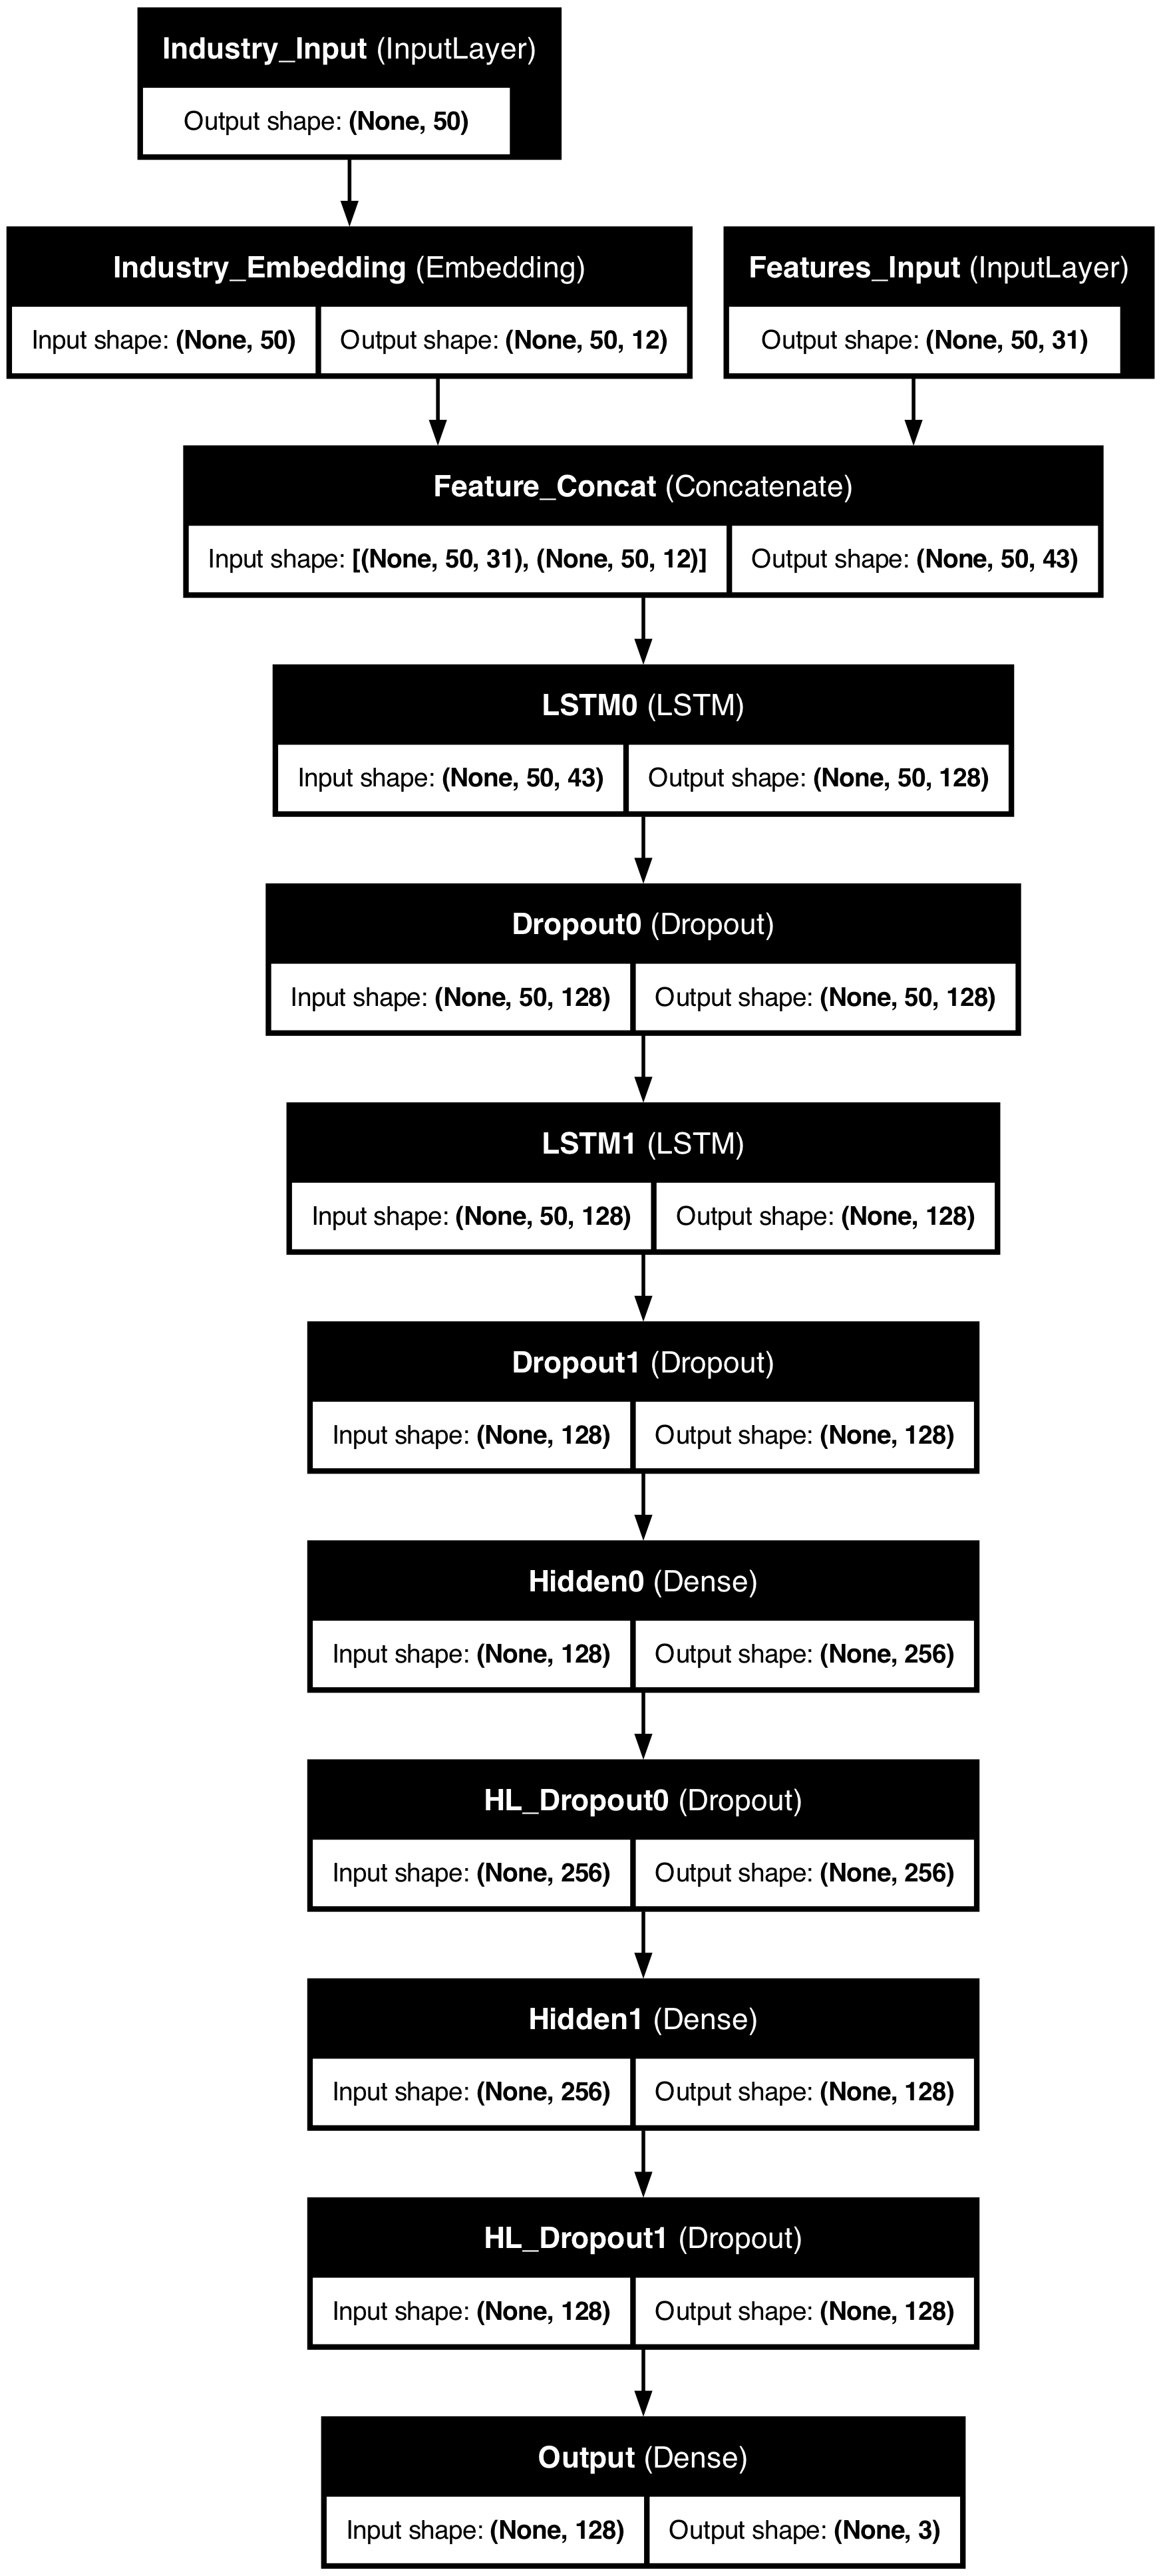

In [92]:
# Also getting the tf graph
display(plot_model(model_LSTM_base, show_shapes=True, show_layer_names=True))

In [80]:
# Fitting the model
model_LSTM_base_fit = model_LSTM_base.fit(
    x={"Features_Input": X_num_train, "Industry_Input": X_embed_train},
    y=Y_train,
    validation_data=({"Features_Input": X_num_test, "Industry_Input": X_embed_test}, Y_test),
    epochs=num_epochs,
    batch_size=batch_size,
    callbacks=[callback],
    verbose=1)

Epoch 1/20
3540/3540 ━━━━━━━━━━━━━━━━━━━━ 92s 26ms/step - Prec_0: 0.6534 - Prec_2: 0.6783 - loss: 1.0925 - val_Prec_0: 0.6262 - val_Prec_2: 0.6365 - val_loss: 1.0831
Epoch 2/20
3540/3540 ━━━━━━━━━━━━━━━━━━━━ 92s 26ms/step - Prec_0: 0.6534 - Prec_2: 0.6783 - loss: 1.0744 - val_Prec_0: 0.6262 - val_Prec_2: 0.6365 - val_loss: 1.0833
Epoch 3/20
3540/3540 ━━━━━━━━━━━━━━━━━━━━ 92s 26ms/step - Prec_0: 0.6534 - Prec_2: 0.6783 - loss: 1.0749 - val_Prec_0: 0.6262 - val_Prec_2: 0.6365 - val_loss: 1.0827
Epoch 4/20
3540/3540 ━━━━━━━━━━━━━━━━━━━━ 89s 25ms/step - Prec_0: 0.6534 - Prec_2: 0.6783 - loss: 1.0753 - val_Prec_0: 0.6262 - val_Prec_2: 0.6365 - val_loss: 1.0849
Epoch 5/20
3540/3540 ━━━━━━━━━━━━━━━━━━━━ 90s 25ms/step - Prec_0: 0.6534 - Prec_2: 0.6783 - loss: 1.0767 - val_Prec_0: 0.6262 - val_Prec_2: 0.6365 - val_loss: 1.0833
Epoch 6/20
3540/3540 ━━━━━━━━━━━━━━━━━━━━ 91s 26ms/step - Prec_0: 0.6534 - Prec_2: 0.6783 - loss: 1.0776 - val_Prec_0: 0.6262 - val_Prec_2: 0.6365 - val_loss: 1.0864


In [82]:
Y_pred = model_LSTM_base.predict(x={"Features_Input": X_num_test, "Industry_Input": X_embed_test})
# Y_pred_thresh = np.where(Y_pred[:, 0] > 0.5, 0,
                         # np.where(Y_pred[:, 2] > 0.5, 2, 1))
Y_pred_thresh = Y_pred.argmax(axis=1)
cf_thresh = confusion_matrix(Y_test, Y_pred_thresh)
cf_thresh

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step


array([[9082, 7461,  694],
       [6209, 9608,  503],
       [8837, 6870,  736]])

In [85]:
# Getting the individual day results in the form of a confusion matrix list
conf_matrix_list = obtain_indiv_day_results(model_LSTM_base, X_num_test, X_embed_test, Y_test, test_size, unique_tickers, 0.5)

# Getting the precision and false positive dictionary for each day
prec_fp_dict = model_eval_indiv_day(conf_matrix_list)

100%|███████████████████████████████████████████| 50/50 [00:11<00:00,  4.35it/s]


In [90]:
hi_test = pd.DataFrame(prec_fp_dict)
display(hi_test['Class 0 Precisions'].mean())
display(hi_test['Class 0 Opposite FP'].mean())

np.float64(0.42798031692696015)

np.float64(0.4272773282238541)

In [98]:
# Why so heavily predicting short???

In [97]:
pd.DataFrame(Y_test).value_counts()

0
0    17237
2    16443
1    16320
Name: count, dtype: int64

In [100]:
# Clearly the test isn't super leaning towards short

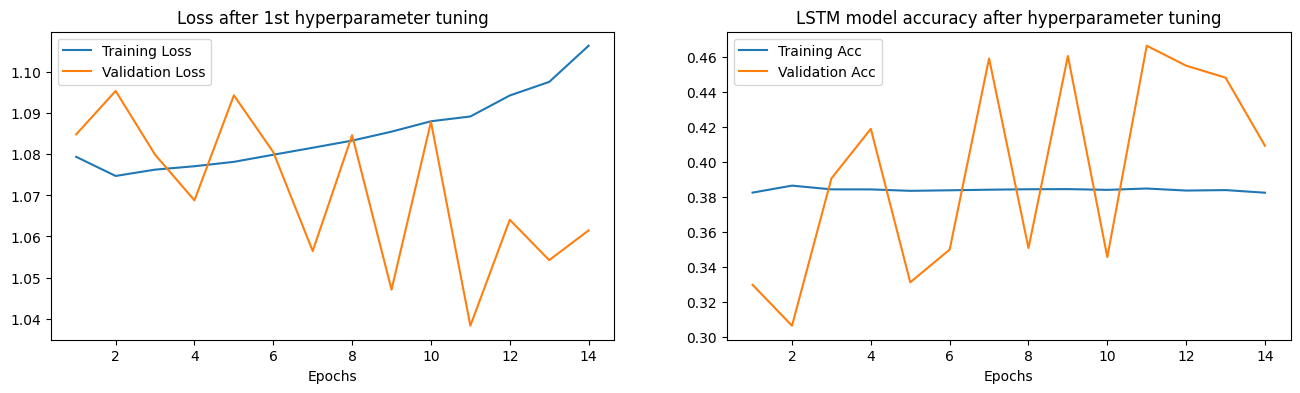

In [26]:
# Plotting the loss on the first subplot
hist_hp_1 = model_LSTM_hp_1_fit.history
epochs_ran = len(hist_hp_1['loss'])
fig = plt.figure(figsize = (16, 4))
ax = fig.add_subplot(1, 2, 1)
plt.plot(range(1, epochs_ran+1), hist_hp_1['loss'], label='Training Loss')
plt.plot(range(1, epochs_ran+1), hist_hp_1['val_loss'], label='Validation Loss')
plt.legend()
ax.set_xlabel('Epochs')
ax.set_title('Loss after 1st hyperparameter tuning');

# Plotting the accuracy on the second subplot
ax = fig.add_subplot(1, 2, 2)
plt.plot(range(1, epochs_ran+1), hist_hp_1['accuracy'], label='Training Acc')
plt.plot(range(1, epochs_ran+1), hist_hp_1['val_accuracy'], label='Validation Acc')
plt.legend()
ax.set_xlabel('Epochs')
ax.set_title('LSTM model accuracy after hyperparameter tuning')
plt.show()

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


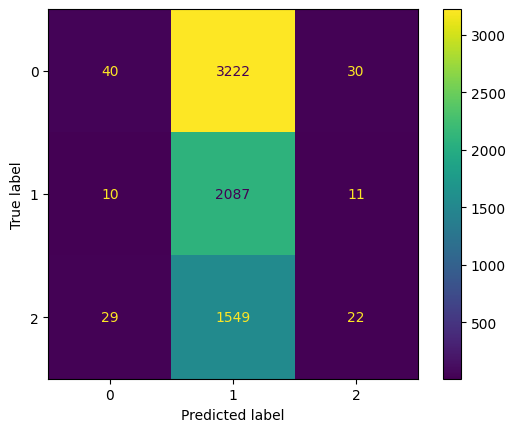

In [27]:
# Obtaining the test predictions
Y_test_hp_1_pred = model_LSTM_hp_1.predict(
  x={"Features_Input": X_num_test, "Industry_Input": X_embed_test})

# Setting a threshold of predictions and getting the confusion matrix
threshold = 0.50
Y_test_hp_1_pred_thresh = np.where(Y_test_hp_1_pred[:, 0] > threshold, 0,
                             np.where(Y_test_hp_1_pred[:, 2] > threshold, 2, 1))

# Getting the confusion matrix for the threshold
cf_thresh_hp_1 = confusion_matrix(
    Y_test,
    Y_test_hp_1_pred_thresh)
disp = ConfusionMatrixDisplay(cf_thresh_hp_1.astype(int))
disp.plot()
plt.show()

In [29]:
# Setting seed for consistent re-runs
tf.random.set_seed(1234)
np.random.seed(1234)

# Setting hyperparameters
seq_length = X_data_small_num.shape[1]
num_features = X_data_small_num.shape[2]
n_classes = 3
num_industries = data_small['Industry_ID'].nunique()
embedding_dim = 5
LSTM_layers = 1
LSTM_units = 128
dropout_rate = 0.3
hidden_layer_sizes = []
activation = 'relu'
learning_rate = 0.0001
optimizer = 'Adam'
metric = 'accuracy'
num_epochs = 10
batch_size = 256

In [33]:
# Building the initial model
model_LSTM_base = build_LSTM_model_func_API_embed(seq_length=seq_length,
                                                  num_features=num_features,
                                                  n_classes=n_classes,
                                                  num_industries=num_industries,
                                                  embedding_dim=embedding_dim,
                                                  LSTM_layers=LSTM_layers,
                                                  LSTM_units=LSTM_units,
                                                  dropout_rate=dropout_rate,
                                                  hidden_layer_sizes=hidden_layer_sizes,
                                                  activation=activation,
                                                  learning_rate=learning_rate,
                                                  optimizer=optimizer,
                                                  metric=metric)
model_LSTM_base.summary()

2025-05-04 14:15:20.683283: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Max
2025-05-04 14:15:20.683344: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2025-05-04 14:15:20.683352: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.00 GB
I0000 00:00:1746382520.683366  467150 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1746382520.683384  467150 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "LSTM_Embed"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Industry_Input      │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Features_Input      │ (None, 50, 31)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Industry_Embedding  │ (None, 50, 5)     │        330 │ Industry_Input[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Concat      │ (None, 50, 36)    │          0 │ Features_Input[0… │
│ (Concatenate)       │                   │            │ Industry_Embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM0 (LSTM)        │ (None, 128)       │     84,480 │ Feature_Concat[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout0 (Dropout)  │ (None, 128)       │          0 │ LSTM0[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Output (Dense)      │ (None, 3)         │        387 │ Dropout0[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 85,197 (332.80 KB)

 Trainable params: 85,197 (332.80 KB)

 Non-trainable params: 0 (0.00 B)

Again, the reason I'm getting the warnings above is because I'm using the GPU from the M4 Max using the metal plugin.

In [24]:
# Confirming that I'm still only using CPU
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


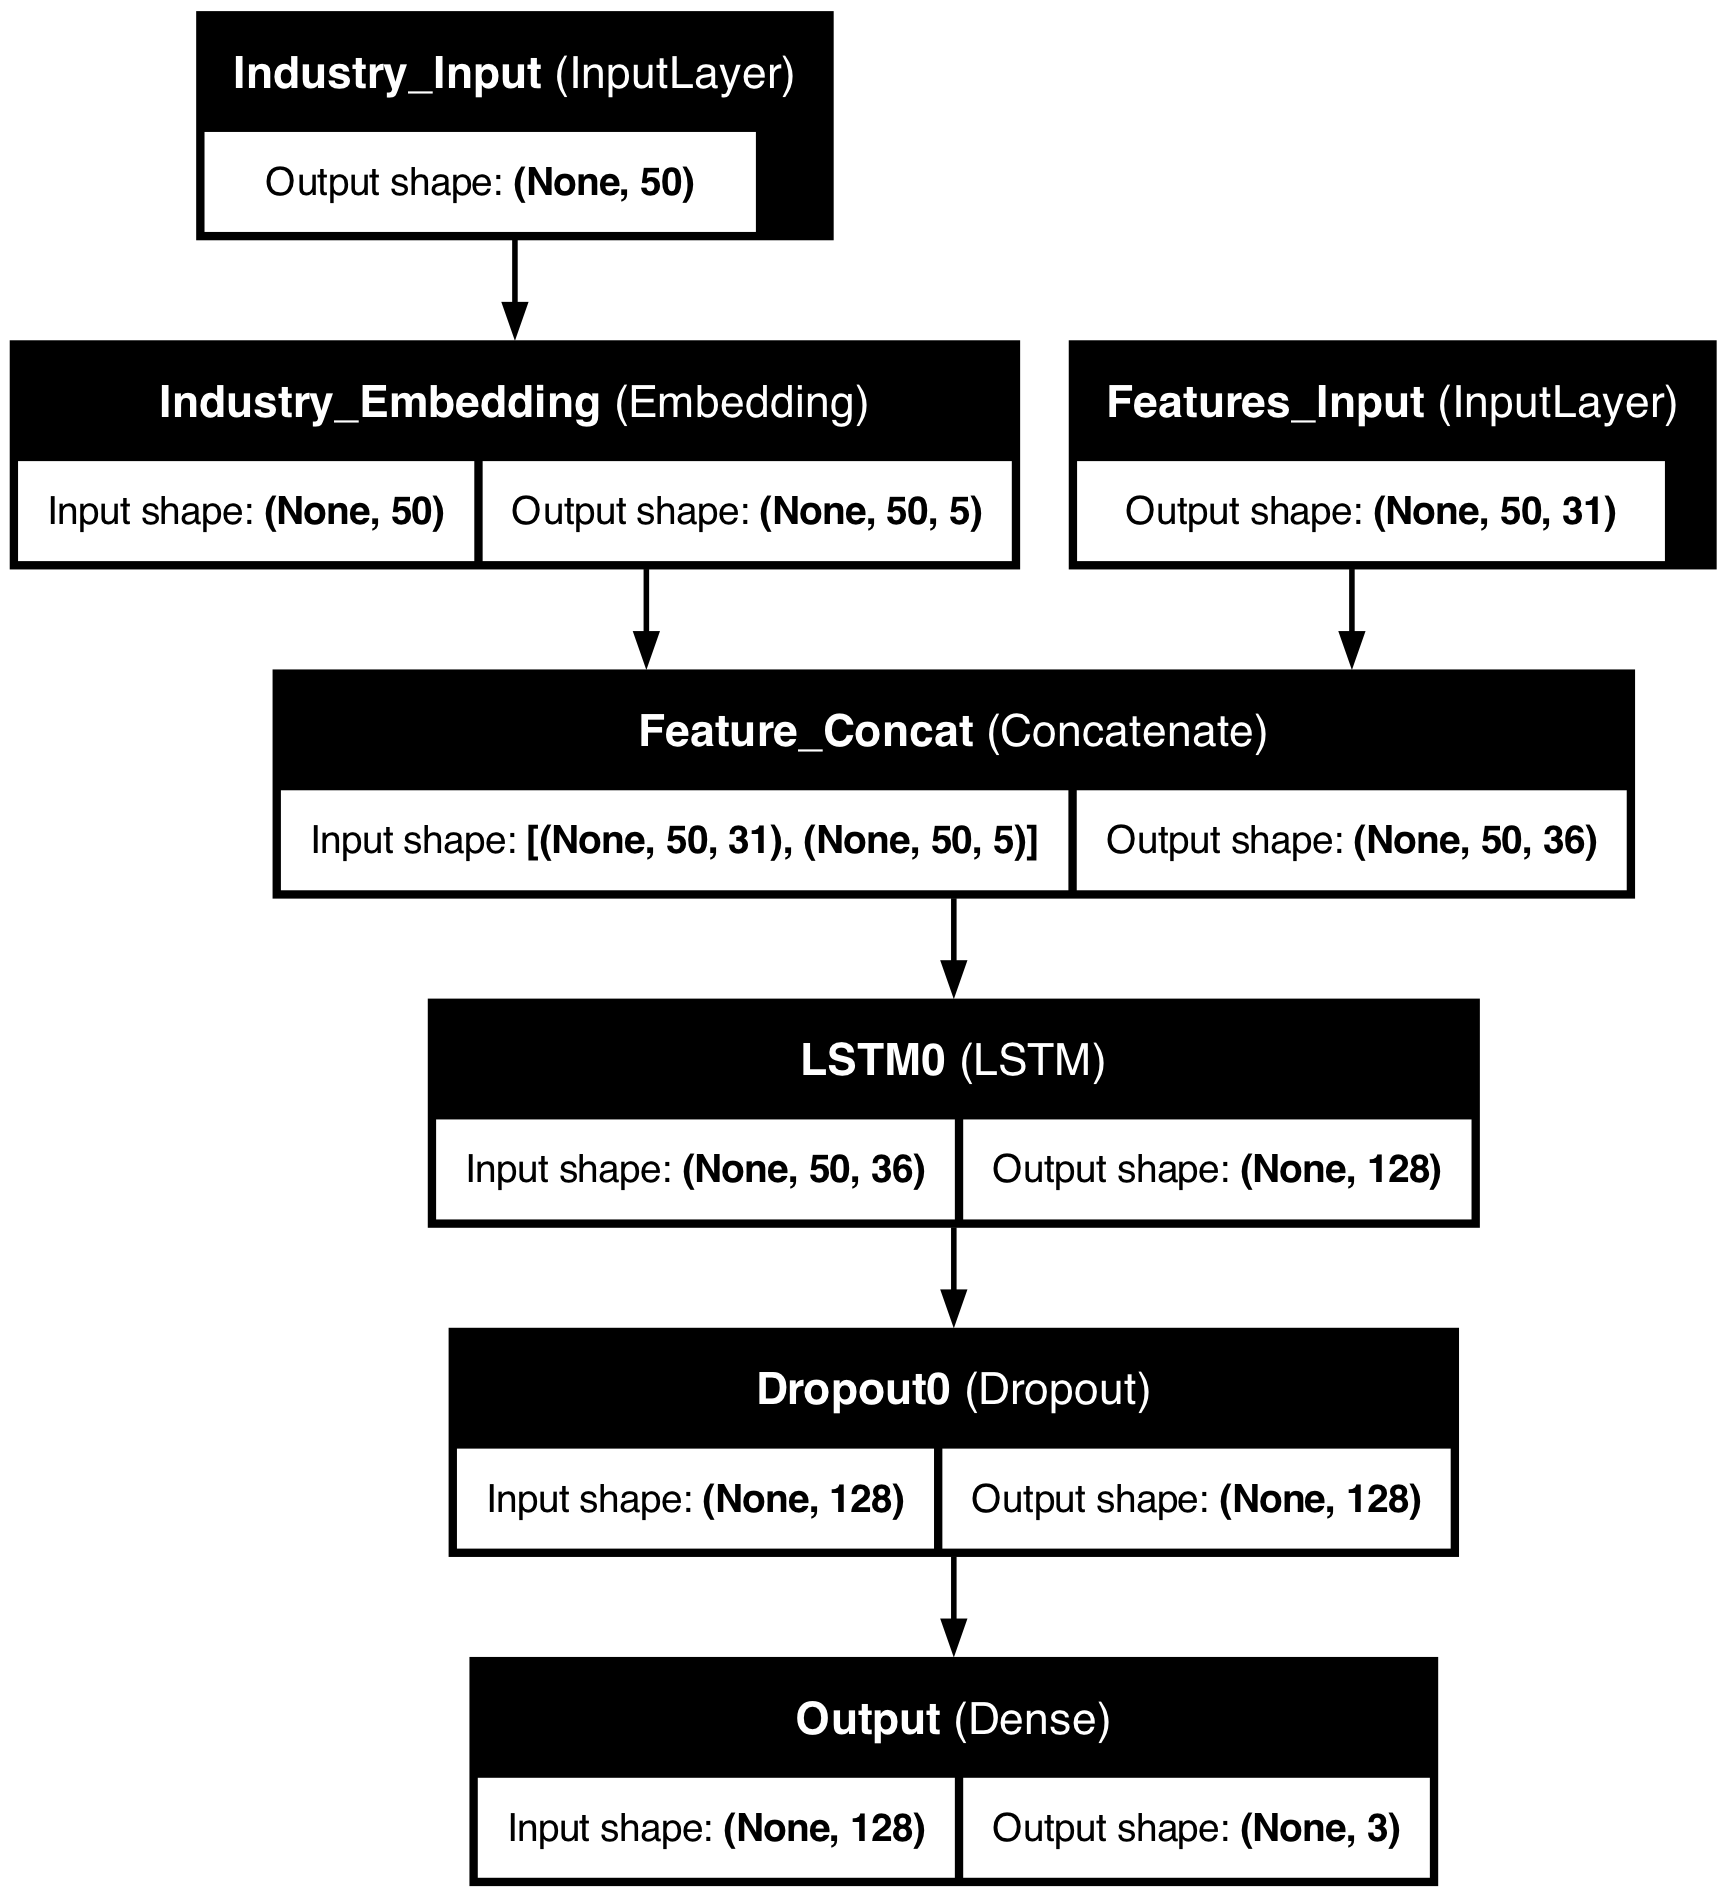

In [21]:
# Also getting the tf graph
display(plot_model(model_LSTM_base, show_shapes=True, show_layer_names=True))

In [22]:
# Fitting the model
model_LSTM_base_fit = model_LSTM_base.fit(
    x={"Features_Input": X_num_train, "Industry_Input": X_embed_train},
    y = Y_train,
    # validation_split = 0.005,
    epochs = num_epochs,
    batch_size = batch_size,
    verbose = 1)

Epoch 1/10


2025-05-01 10:21:33.843916: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


3708/3708 ━━━━━━━━━━━━━━━━━━━━ 48s 12ms/step - accuracy: 0.3778 - loss: 1.0865
Epoch 2/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 45s 12ms/step - accuracy: 0.3927 - loss: 1.0732
Epoch 3/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 45s 12ms/step - accuracy: 0.3971 - loss: 1.0713
Epoch 4/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 46s 12ms/step - accuracy: 0.3979 - loss: 1.0705
Epoch 5/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 46s 12ms/step - accuracy: 0.3989 - loss: 1.0699
Epoch 6/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 46s 12ms/step - accuracy: 0.4012 - loss: 1.0694
Epoch 7/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - accuracy: 0.4021 - loss: 1.0689
Epoch 8/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 46s 13ms/step - accuracy: 0.4031 - loss: 1.0686
Epoch 9/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - accuracy: 0.4041 - loss: 1.0682
Epoch 10/10
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - accuracy: 0.4049 - loss: 1.0678


While the accuracy still isn't great, this base run only took ~8 minutes (46 seconds per epoch) (compared to 40 minutes when using the CPU). I'll first check what the actual results look like for the rest run, but I'll likely incorporate the test data as validation data, and I'll use data from 2025 be my "true" test data.

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


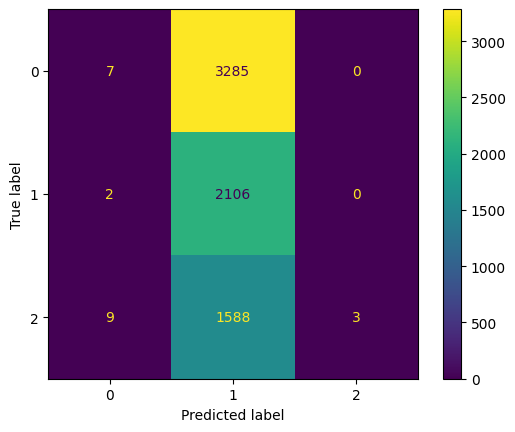

In [23]:
# Obtaining the test predictions
Y_test_base_pred = model_LSTM_base.predict(
  x={"Features_Input": X_num_test, "Industry_Input": X_embed_test})

# Setting a threshold of predictions and getting the confusion matrix
threshold = 0.5
Y_test_base_pred_thresh = np.where(Y_test_base_pred[:, 0] > threshold, 0,
                             np.where(Y_test_base_pred[:, 2] > threshold, 2, 1))

# Getting the confusion matrix for the threshold
cf_thresh = confusion_matrix(
    Y_test,
    Y_test_base_pred_thresh)
disp = ConfusionMatrixDisplay(cf_thresh.astype(int))
disp.plot()
plt.show()

So, it's clear that even across 7 days, with a threshold of 0.5, the model did not perform great. It barely took any trades, and the trades that it did take (especially on the short side) were quite wrong. This at least somewhat makes sense, as we no longer have the Open price in our data anymore, which was likely the biggest determinant of the prediction. However, I have not done any hyperparameter tuning, and it's likely the model can improve at least a bit. In particular, with the GPU, I can probably perform some more aggressive hyperparameter tuning to really improve the model (hidden layers, more LSTM layers, etc.).

## Hyperparameter-tuned model 1
This is my first iteration of hyperparameter tuning after switching to using the M4 Max Macbook's GPU for training.

In [22]:
# Setting seed for consistent re-runs
tf.random.set_seed(1234)
np.random.seed(1234)

# Setting hyperparameters
seq_length = X_data_small_num.shape[1]
num_features = X_data_small_num.shape[2]
n_classes = 3
num_industries = data_small['Industry_ID'].nunique()
embedding_dim = 12
LSTM_layers = 2
LSTM_units = 128
dropout_rate = 0.3
hidden_layer_sizes = [256, 128]
activation = 'relu'
learning_rate = 0.001
optimizer = 'Adam'
metric = 'accuracy'
num_epochs = 20
batch_size = 256
callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)

In [23]:
# Building the initial model
model_LSTM_hp_1 = build_LSTM_model_func_API_embed(seq_length=seq_length,
                                                  num_features=num_features,
                                                  n_classes=n_classes,
                                                  num_industries=num_industries,
                                                  embedding_dim=embedding_dim,
                                                  LSTM_layers=LSTM_layers,
                                                  LSTM_units=LSTM_units,
                                                  dropout_rate=dropout_rate,
                                                  hidden_layer_sizes=hidden_layer_sizes,
                                                  activation=activation,
                                                  learning_rate=learning_rate,
                                                  optimizer=optimizer,
                                                  metric=metric)
model_LSTM_hp_1.summary()

2025-05-03 16:23:00.426888: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Max
2025-05-03 16:23:00.427023: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2025-05-03 16:23:00.427036: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.00 GB
I0000 00:00:1746303780.427571   22293 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1746303780.427613   22293 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "LSTM_Embed"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Industry_Input      │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Features_Input      │ (None, 50, 31)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Industry_Embedding  │ (None, 50, 12)    │        792 │ Industry_Input[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Concat      │ (None, 50, 43)    │          0 │ Features_Input[0… │
│ (Concatenate)       │                   │            │ Industry_Embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM0 (LSTM)        │ (None, 50, 128)   │     88,064 │ Feature_Concat[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout0 (Dropout)  │ (None, 50, 128)   │          0 │ LSTM0[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM1 (LSTM)        │ (None, 128)       │    131,584 │ Dropout0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout1 (Dropout)  │ (None, 128)       │          0 │ LSTM1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Hidden0 (Dense)     │ (None, 256)       │     33,024 │ Dropout1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ HL_Dropout0         │ (None, 256)       │          0 │ Hidden0[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Hidden1 (Dense)     │ (None, 128)       │     32,896 │ HL_Dropout0[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ HL_Dropout1         │ (None, 128)       │          0 │ Hidden1[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Output (Dense)      │ (None, 3)         │        387 │ HL_Dropout1[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 286,747 (1.09 MB)

 Trainable params: 286,747 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Fitting the model
model_LSTM_hp_1_fit = model_LSTM_hp_1.fit(
    x={"Features_Input": X_num_train, "Industry_Input": X_embed_train},
    y=Y_train,
    validation_data=({"Features_Input": X_num_test, "Industry_Input": X_embed_test}, Y_test),
    epochs=num_epochs,
    batch_size=batch_size,
    callbacks=[callback],
    verbose=1)

Epoch 1/20


2025-05-01 12:00:05.006973: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


3708/3708 ━━━━━━━━━━━━━━━━━━━━ 71s 19ms/step - accuracy: 0.3770 - loss: 1.0870 - val_accuracy: 0.3297 - val_loss: 1.0849
Epoch 2/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 71s 19ms/step - accuracy: 0.3872 - loss: 1.0745 - val_accuracy: 0.3063 - val_loss: 1.0955
Epoch 3/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 72s 19ms/step - accuracy: 0.3853 - loss: 1.0754 - val_accuracy: 0.3906 - val_loss: 1.0799
Epoch 4/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 71s 19ms/step - accuracy: 0.3840 - loss: 1.0771 - val_accuracy: 0.4190 - val_loss: 1.0688
Epoch 5/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 73s 20ms/step - accuracy: 0.3835 - loss: 1.0779 - val_accuracy: 0.3311 - val_loss: 1.0944
Epoch 6/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 73s 20ms/step - accuracy: 0.3835 - loss: 1.0797 - val_accuracy: 0.3499 - val_loss: 1.0805
Epoch 7/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 72s 19ms/step - accuracy: 0.3852 - loss: 1.0808 - val_accuracy: 0.4593 - val_loss: 1.0564
Epoch 8/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 73s 20ms/step - accuracy: 0.3853 - loss: 1.08

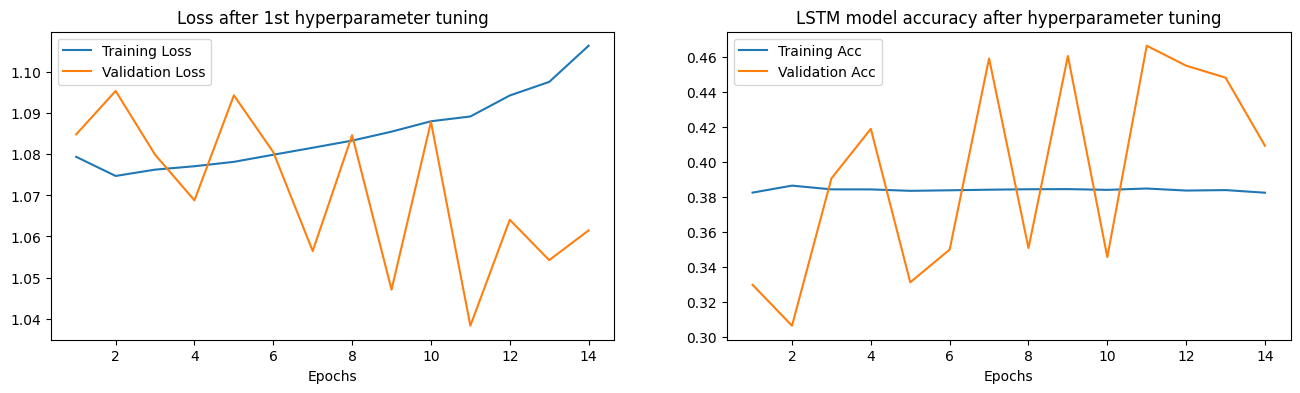

In [26]:
# Plotting the loss on the first subplot
hist_hp_1 = model_LSTM_hp_1_fit.history
epochs_ran = len(hist_hp_1['loss'])
fig = plt.figure(figsize = (16, 4))
ax = fig.add_subplot(1, 2, 1)
plt.plot(range(1, epochs_ran+1), hist_hp_1['loss'], label='Training Loss')
plt.plot(range(1, epochs_ran+1), hist_hp_1['val_loss'], label='Validation Loss')
plt.legend()
ax.set_xlabel('Epochs')
ax.set_title('Loss after 1st hyperparameter tuning');

# Plotting the accuracy on the second subplot
ax = fig.add_subplot(1, 2, 2)
plt.plot(range(1, epochs_ran+1), hist_hp_1['accuracy'], label='Training Acc')
plt.plot(range(1, epochs_ran+1), hist_hp_1['val_accuracy'], label='Validation Acc')
plt.legend()
ax.set_xlabel('Epochs')
ax.set_title('LSTM model accuracy after hyperparameter tuning')
plt.show()

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


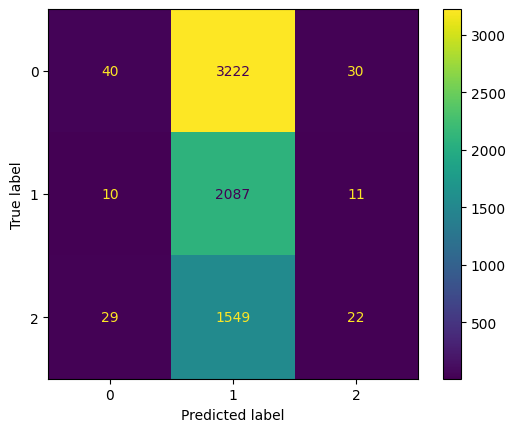

In [27]:
# Obtaining the test predictions
Y_test_hp_1_pred = model_LSTM_hp_1.predict(
  x={"Features_Input": X_num_test, "Industry_Input": X_embed_test})

# Setting a threshold of predictions and getting the confusion matrix
threshold = 0.50
Y_test_hp_1_pred_thresh = np.where(Y_test_hp_1_pred[:, 0] > threshold, 0,
                             np.where(Y_test_hp_1_pred[:, 2] > threshold, 2, 1))

# Getting the confusion matrix for the threshold
cf_thresh_hp_1 = confusion_matrix(
    Y_test,
    Y_test_hp_1_pred_thresh)
disp = ConfusionMatrixDisplay(cf_thresh_hp_1.astype(int))
disp.plot()
plt.show()

I tested with a number of different hyperparameter combinations, but I found this one to be particularly interesting. Notably, it was extremely choppy, and it didn't do well at all. More importantly, **the validation accuracy does not reflect how well the model does whatsoever**. This is primarily because it focuses on all the classes, not just Class 0 and 2 (which we care about). And since class 1 is so large, it gets the majority of the predictions.

There are two things I need to do now: 1) integrate the sliding window model to get a better representation of how well my model does across multiple days, and 2) figure out a way to weigh the errors on Class 0 and 2 more heavily; basically, if my model predicts 1, have it not worry much about whether it's right or wrong. However, if it predicts 0 or 2, it should be punished more heavily for getting it wrong. I'll also consider getting rid of the validation accuracy afterward as it's not giving me any valuable insight into model performance.

## HP-tuned model with sample weights
I'm trying something different here: instead of just predicting 0, 1, or 2, I'm going to include sample weights so that large changes in the price action will be penalized more heavily.

In [104]:
# Getting the Close_Open_Diff_Perc column and helper columns
df_C_O_Diff_Perc = df_1000.copy()
df_C_O_Diff_Perc = df_C_O_Diff_Perc[['Datetime', 'Ticker', 'Close_Open_Diff_Perc', 'Rank']]

# If Rank is less than or equal to the number of 99 (50 for NA_days + 49 for sequence length, drop the row to match w/ previous data)
drop_days_rank = 99
df_C_O_Diff_Perc = df_C_O_Diff_Perc[df_C_O_Diff_Perc['Rank'] > drop_days_rank]

# Dropping the last 7 ranks for each day (since they're all test days)
test_days_rank = 1049
df_C_O_Diff_Perc = df_C_O_Diff_Perc[df_C_O_Diff_Perc['Rank'] < test_days_rank]

# Sorting by Datetime, and then by Ticker
df_C_O_Diff_Perc = df_C_O_Diff_Perc.sort_values(by=['Datetime', 'Ticker'])

# Seeing the 25%/75% quartile ranges and the 0.1%/99.9% quantile range
display(df_C_O_Diff_Perc.describe())
display(df_C_O_Diff_Perc['Close_Open_Diff_Perc'].quantile([0.001,0.999]))

,Datetime,Close_Open_Diff_Perc,Rank
count,949000,949000.000000,949000.000000
mean,2023-01-11 07:44:19.220232448,0.023973,574.000000
min,2021-02-24 00:00:00,-50.081235,100.000000
25%,2022-02-01 00:00:00,-0.907576,337.000000
50%,2023-01-11 00:00:00,0.029959,574.000000
75%,2023-12-20 00:00:00,0.945441,811.000000
max,2024-11-29 00:00:00,283.157895,1048.000000
std,NaN,1.910267,273.952695


0.001    -9.435220
0.999    10.307805
Name: Close_Open_Diff_Perc, dtype: float64

Given that ~99.8% of the Close prices fit within ~±10% of their Open prices for that day, we can clip the outliers to that ±10% figure. This has the benefit of reducing the outlier noise in our data, while also allowing us to visualize the data better.

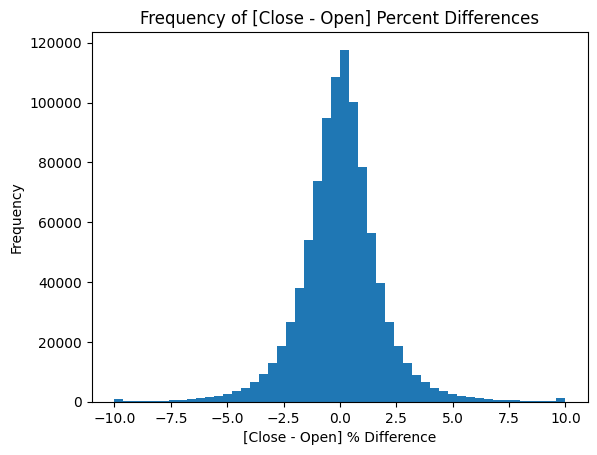

In [105]:
# Getting the clipped percents and visualizing their distribution on a histogram
clipped_perc = np.clip(df_C_O_Diff_Perc['Close_Open_Diff_Perc'], -10, 10)
plt.hist(clipped_perc, bins=50)
plt.xlabel('[Close - Open] % Difference')
plt.ylabel('Frequency')
plt.title('Frequency of [Close - Open] Percent Differences')
plt.show()

Overall, the data seems at least somewhat normal, though the data is more centralized. Either way, normality is not a condition to run our models, and we can assign sample weights to our data to account for larger changes in Close-Open % Difference. We'll also implement a 10% maximum weight limit to keep the weights in reasonable bounds.

In [106]:
# Creating sample weights for the model (with a max limit 10 for the weight)
sample_weights = np.abs(df_C_O_Diff_Perc['Close_Open_Diff_Perc'].values)
sample_weights = np.clip(sample_weights, 0, 10.0)  # Keeping the lower bound at 0 because...

In [107]:
# Building the sample weight model the same exact way as before
model_LSTM_sw_1 = build_LSTM_model_func_API_embed(seq_length=seq_length,
                                                  num_features=num_features,
                                                  n_classes=n_classes,
                                                  num_industries=num_industries,
                                                  embedding_dim=embedding_dim,
                                                  LSTM_layers=LSTM_layers,
                                                  LSTM_units=LSTM_units,
                                                  dropout_rate=dropout_rate,
                                                  hidden_layer_sizes=hidden_layer_sizes,
                                                  activation=activation,
                                                  learning_rate=learning_rate,
                                                  optimizer=optimizer,
                                                  metric=metric)
# model_LSTM_sw_1.summary()

In [108]:
# Fitting the model, but with the added sample weights
model_LSTM_sw_1_fit = model_LSTM_sw_1.fit(
    x={"Features_Input": X_num_train, "Industry_Input": X_embed_train},
    y=Y_train,
    validation_data=({"Features_Input": X_num_test, "Industry_Input": X_embed_test}, Y_test),
    epochs=num_epochs,
    batch_size=batch_size,
    callbacks=[callback],
    sample_weight=sample_weights,
    verbose=1)

Epoch 1/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 91s 24ms/step - accuracy: 0.3556 - loss: 1.1390 - val_accuracy: 0.4294 - val_loss: 1.2796
Epoch 2/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 94s 25ms/step - accuracy: 0.3577 - loss: 1.1163 - val_accuracy: 0.4599 - val_loss: 1.3199
Epoch 3/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 93s 25ms/step - accuracy: 0.3574 - loss: 1.1200 - val_accuracy: 0.4647 - val_loss: 1.2803
Epoch 4/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 96s 26ms/step - accuracy: 0.3594 - loss: 1.1192 - val_accuracy: 0.4639 - val_loss: 1.3255


The training accuracy was pretty abysmal, while the validation accuracy seemed to perform better. However, I realize now that both of these accuracy figures are somewhat pointless, as **all** we care about are the precisions for Class 0 and Class 2. Furthermore, we're evaluating over 7 test days, which heavily takes away from the "realness" of our model since we'll have all the data leading up to that day to use for prediction. Thus, after I perform the requisite test prediction analysis, I'm going to stop using the validation data, create the sliding window model, and find other ways to emphasize Class 0 and 2.

First trying a prediction threshold of 0.55:

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


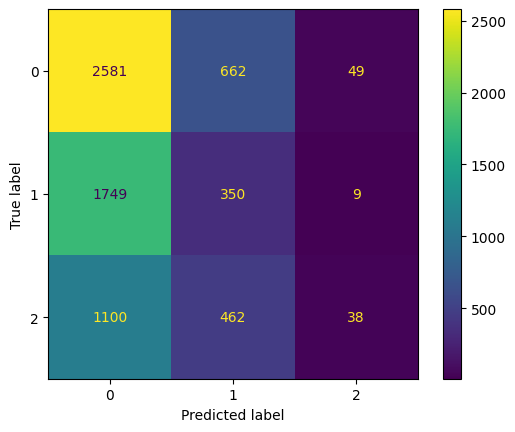

In [126]:
# Obtaining the test predictions
Y_test_sw_1_pred = model_LSTM_sw_1.predict(
  x={"Features_Input": X_num_test, "Industry_Input": X_embed_test})

# Setting a threshold of predictions and getting the confusion matrix
threshold = 0.55
Y_test_sw_1_pred_thresh = np.where(Y_test_sw_1_pred[:, 0] > threshold, 0,
                             np.where(Y_test_sw_1_pred[:, 2] > threshold, 2, 1))

# Getting the confusion matrix for the threshold
cf_thresh_sw_1 = confusion_matrix(
    Y_test,
    Y_test_sw_1_pred_thresh)
disp_sw_1 = ConfusionMatrixDisplay(cf_thresh_sw_1.astype(int))
disp_sw_1.plot()
plt.show()

And now trying a prediction threshold of 0.60:

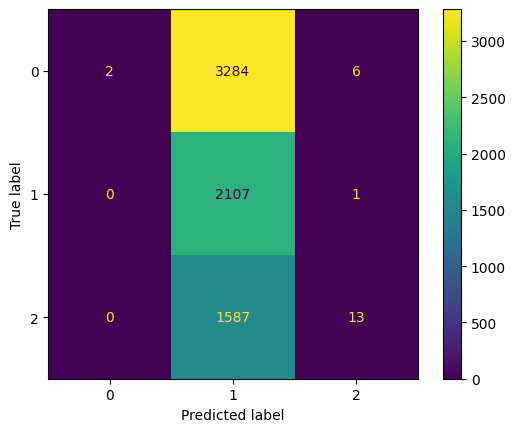

In [127]:
# Setting a threshold of predictions and getting the confusion matrix
threshold = 0.60
Y_test_sw_1_pred_thresh = np.where(Y_test_sw_1_pred[:, 0] > threshold, 0,
                             np.where(Y_test_sw_1_pred[:, 2] > threshold, 2, 1))

# Getting the confusion matrix for the threshold
cf_thresh_sw_1 = confusion_matrix(
    Y_test,
    Y_test_sw_1_pred_thresh)
disp_sw_1 = ConfusionMatrixDisplay(cf_thresh_sw_1.astype(int))
disp_sw_1.plot()
plt.show()

In [124]:
# Displaying the true counts of Y_test
pd.DataFrame(Y_test).value_counts()

0
0    3292
1    2108
2    1600
Name: count, dtype: int64

In [125]:
# Displaying the actual argmax predictions of our model
pd.DataFrame(Y_test_sw_1_pred.argmax(axis=1)).value_counts()

0
0    6645
2     355
Name: count, dtype: int64

Ok, with these results, I believe I'm running into another big problem, specifically with classification as a whole. With the sample weights I implemented, while it does proportionally penalize incorrect class predictions based on how far away they are, it does so evenly with both the other classes. To describe what I mean, let's say the true Class is 0 for a particular observation, and let's assume the Close-Open Diff is -10%. In that case, whether the model predicts Class 1 or Class 2, they're both going to be punished **the same amount**. Therefore, the model doesn't penalize Class 2 more heavily than Class 1, which is what I want.

I believe this is happening because of the inherent nature of classification models. **While we as humans know that there's clearly an ordinal relationship between Class 0, 1, and 2, the model has no idea that the Class 1 values are always less than those in Class 2, and the values in Class 0 are always less than those in Class 1**.

I've attempted to account for this by using prediction thresholds and now sample weights, but I don't believe I'm getting the desired result. In the example above, while there definitely are more values in Class 0 than the other two, my model predicted ~95% of the values to be in Class 0, with only ~5% of the values belonging to Class 2 and **0** predictions for Class 1. This is likely explained by the model not weighing Class 1 heavily - because by how it's defined, Class 1 values will always be <0.5% when it comes to weighting - which ultimately causes it to hone in on correctly predicting Class 0 or Class 2 and learn what combination of features can push the prediction towards those two classes.

While the prediction threshold does attempt to address the issue above, it's apparently extremely sensitive. Going from a threshold of 0.55 to 0.60 essentially pushes all the predictions to Class 1, indicating that the model is almost never at least ~60% confident. This is quite troublesome, and it's impossible to trust a model that is this sensitive.

I'll do another check with the training data to see what the splits are:

In [130]:
Y_train_sw_1_pred = model_LSTM_sw_1.predict(
  x={"Features_Input": X_num_train, "Industry_Input": X_embed_train})
pd.DataFrame(Y_train_sw_1_pred.argmax(axis=1)).value_counts()

29657/29657 ━━━━━━━━━━━━━━━━━━━━ 210s 7ms/step


0
0    809393
2    139607
Name: count, dtype: int64

And this reveals that even with the training data, the Class 0 to Class 2 predictions split is roughly 85:15, with no predictions for Class 1 again. The reason might be that heavier drops are more common with Class 0, and we can check this below: 

In [138]:
# Checking the average sample weights for the 3 Classes:
print("Average sample weights for Class:")
print(" - 0:", np.mean(sample_weights[Y_train == 0]))
print(" - 1:", np.mean(sample_weights[Y_train == 1]))
print(" - 2:", np.mean(sample_weights[Y_train == 2]))

Average sample weights for Class:
 - 0: 1.7369687129111064
 - 1: 0.2446537211173817
 - 2: 1.7251221013598947


And unfortunately, we see that this is clearly not the problem, as we notice that the sample weights are roughly equal between Class 0 and Class 2 (Class 1 is expectedly lower as it's only between -0.5% and +0.5%).

## HP-tuned model with class weights
I'm going to take a pause on using sample weights, and I'll experiment with using class weights instead. I've tried this in the past, to no avail, but I didn't implemented the prediction thresholds previously. Thus, I'll try implementing class weights again (ignoring Class 1), and then use the prediction threshold to obtain my final predictions.

In [143]:
# Building the initial class weighted model
model_LSTM_cw_1 = build_LSTM_model_func_API_embed(seq_length=seq_length,
                                                  num_features=num_features,
                                                  n_classes=n_classes,
                                                  num_industries=num_industries,
                                                  embedding_dim=embedding_dim,
                                                  LSTM_layers=LSTM_layers,
                                                  LSTM_units=LSTM_units,
                                                  dropout_rate=dropout_rate,
                                                  hidden_layer_sizes=hidden_layer_sizes,
                                                  activation=activation,
                                                  learning_rate=learning_rate,
                                                  optimizer=optimizer,
                                                  metric=metric)
# model_LSTM_hp_1.summary()

In [144]:
# Defining the class weight dictionary (Class 0 and 2 will be weighted 1, and Class 0 will be ignored)
class_weight = {0: 1.0,
                1: 0.0,
                2: 1.0}

# Fitting the model (and only keeping the validation data for the callback)
model_LSTM_cw_1_fit = model_LSTM_cw_1.fit(
    x={"Features_Input": X_num_train, "Industry_Input": X_embed_train},
    y=Y_train,
    validation_data=({"Features_Input": X_num_test, "Industry_Input": X_embed_test}, Y_test),
    epochs=num_epochs,
    batch_size=batch_size,
    class_weight=class_weight,
    callbacks=[callback],
    verbose=1)

Epoch 1/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 94s 25ms/step - accuracy: 0.3547 - loss: 0.5066 - val_accuracy: 0.2286 - val_loss: 4.8458
Epoch 2/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 96s 26ms/step - accuracy: 0.3558 - loss: 0.4904 - val_accuracy: 0.3584 - val_loss: 7.0730
Epoch 3/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 93s 25ms/step - accuracy: 0.3553 - loss: 0.4918 - val_accuracy: 0.4703 - val_loss: 10.3077
Epoch 4/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 96s 26ms/step - accuracy: 0.3569 - loss: 0.4916 - val_accuracy: 0.3874 - val_loss: 15.1624


Again, the accuracy figures are irrelevant, and we only care about the precisions as shown in the next cell.

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


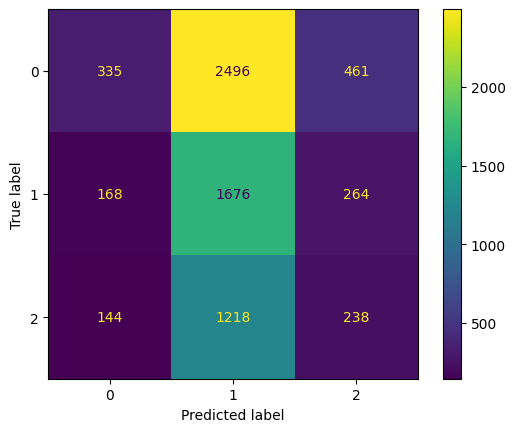

In [155]:
# Obtaining the test predictions
Y_test_cw_1_pred = model_LSTM_cw_1.predict(
  x={"Features_Input": X_num_test, "Industry_Input": X_embed_test})

# Setting a threshold of predictions and getting the confusion matrix
threshold = 0.53
Y_test_cw_1_pred_thresh = np.where(Y_test_cw_1_pred[:, 0] > threshold, 0,
                             np.where(Y_test_cw_1_pred[:, 2] > threshold, 2, 1))

# Getting the confusion matrix for the threshold
cf_thresh_cw_1 = confusion_matrix(
    Y_test,
    Y_test_cw_1_pred_thresh)
disp_cw_1 = ConfusionMatrixDisplay(cf_thresh_cw_1.astype(int))
disp_cw_1.plot()
plt.show()

Well, it appears that even though we only focused on Class 0 and 2 with a prediction threshold of 0.53 (the best one), the predictions were still awful. This indicates that even with all the additional features and the updated model architecture, the model still has an incredibly difficult time differentiating between these two classes.

# Conclusion for prediction thresholds, sample weights, class weights, and classification
In the end, I'm running into numerous issues with trying to properly weigh the different classes. While I want Class 0 and Class 2 to be weighted more heavily, it seems quite cumbersome with the tools I have on hand.

The first method I tried was simply using prediction thresholds, but that only comes into play during inference and not during model training. In my case, while prediction thresholds did provide better results in the end, it's almost like putting on a Band-Aid to mask how well the model actually performs.

My next method was using sample weights to both penalize and reward Class 0 and 2 predictions more heavily, and while it did have the intended effect of eliminating predictions for Class 1, the data was skewed greatly towards Class 0. As of now, I do not have an explanation as to why this is the case, but my hypothesis is that even though the average sample weights for Class 0 and Class 2 are roughly equal, even minute differences may cause large changes in outcomes. I was thinking of using a temperature-scaled softmax to reduce the confidence my model has in a certain class, but this is also only done at inference and will likely be pretty comparable to how I implemented my prediction threshold.

Another thought is that the signals are just simply more indicative when the price is about to drop, which increases the model confidence when predicting short. However, it's systematically predicting short with a softmax confidence of 0.55-0.60, which leads me to believe that there's another underlying issue. I could try making the sample weight difference a bit less extreme to see if that solves the problem (i.e., instead of 0 to 10, maybe add a buffer of 10 so that it scales from 10 to 20); however, I believe there's a better way to solve this problem.

Instead of performing classification like I always have, I would like to do something more akin to linear regression. More specifically, instead of having my final layer be a softmax, I want to try predicting the Close-Open Diff percents themselves. I've avoided doing so because I believed that classification was easier to understand and measure (since I could clearly differentiate between the 3 classes and predict exactly what to do in each situation). However, I don't believe there's any reason why a linear activation function couldn't do the same thing. Specifically, if I just follow my predictions for the highest % changes in the short and long directions, that should hopefully give me the best chance of success.

A linear activation function at the end of my model also has the benefit of not needing to worry about the ordinality of my classes. As I mentioned, the major problem that always came up when doing classification was that the model couldn't punish "opposite" class predictions (Class 0 vs Class 2) more heavily than "neutral" class predictions (Class 0/2 vs Class 1). The prediction thresholds, sample weighting, and class weighting techniques were ways to try to get around that, but none of them had much success. If I instead use a linear activation function in the end, I don't need to worry about any of these factors, as it will automatically know that short values are smaller than neutral values, which are then smaller than positive values.

One last thing I'll try before using the linear activation function is the coral ordinal function described here: https://github.com/ck37/coral-ordinal?tab=readme-ov-file. Basically, the authors attempted to devise a way to implement ordinality into their class predictions, using OrdinalCrossEntropy as the loss and MeanAbsoluteErrorLabels as the metric. From what I understand, they seem to address the ordinality between classes by changing the loss to reflect that, and I'll try testing it out to see how it performs.

## (Optional) Additional test with ordinal regression
I will be using the https://github.com/ck37/coral-ordinal?tab=readme-ov-file library to test out whether defining the variables as ordinal will help with model performance.

In [18]:
# Importing coral ordinal package
import coral_ordinal as coral

In [33]:
# Defining new function to build and compile model with everything above plus the Coral Ordinal output and loss
def build_LSTM_model_coral_ord(seq_length,
                                    num_features,  # Excluding Industry
                                    n_classes,
                                    num_industries,
                                    embedding_dim=5,
                                    LSTM_layers=1,
                                    LSTM_units=128,
                                    dropout_rate=0.3,
                                    hidden_layer_sizes=[],
                                    activation='relu',
                                    learning_rate=0.0001,
                                    optimizer='Adam'):

    # Resetting tf for consistent results
    tf.keras.backend.clear_session()
    np.random.seed(0)
    tf.random.set_seed(0)

    # Getting the Input features
    features_input = Input(shape=(seq_length, num_features), name='Features_Input')
    industry_input = Input(shape=(seq_length,), dtype='int32', name='Industry_Input')

    # Getting the embedding for Industry
    industry_embedded = Embedding(input_dim=num_industries, output_dim=embedding_dim, name='Industry_Embedding')(industry_input)

    # Concatenating embedded industry with features (shape: (batch, seq_length, num_features + embedding_dim))
    x = Concatenate(axis=-1, name='Feature_Concat')([features_input, industry_embedded])

    # Getting the LSTM and Dropout layers
    for i in range(LSTM_layers):
        
        LSTM_return_sequences = True
        if i + 1 == LSTM_layers:
            LSTM_return_sequences = False
        
        LSTM_layer_name = 'LSTM' + str(i)
        x = LSTM(units=LSTM_units, return_sequences=LSTM_return_sequences, name=LSTM_layer_name)(x)

        LSTM_dropout_name = 'Dropout' + str(i)
        x = Dropout(dropout_rate, name=LSTM_dropout_name)(x)

    # Adding in hidden layers and dropout layers
    for idx, hidden_layer_size in enumerate(hidden_layer_sizes):
        hidden_layer_name = 'Hidden' + str(idx)
        x = Dense(units=hidden_layer_size, activation=activation, name=hidden_layer_name)(x)
        HL_dropout_name = 'HL_Dropout' + str(idx)
        x = Dropout(dropout_rate, name=HL_dropout_name)(x)
    
    # Finishing with the coral ordinal layer
    output = coral.CoralOrdinal(num_classes=n_classes)(x)

    model = tf.keras.Model(inputs=[features_input, industry_input], outputs=output, name='LSTM_Coral_Ord')
    
    # Compiling the model
    optimizer_class = getattr(tf.keras.optimizers, optimizer)
    optimizer_instance = optimizer_class(learning_rate=learning_rate)
    model.compile(optimizer=optimizer_instance,
                  loss=coral.OrdinalCrossEntropy())  # Changed to coral ordinal
                  # metrics=[coral.MeanAbsoluteErrorLabels()])  # Not implementing because of versioning issues with code and Keras
    
    return model

In [50]:
# Setting seed for consistent re-runs
tf.random.set_seed(1234)
np.random.seed(1234)

# Setting hyperparameters for coral ordinal output (metric defined in function as coral.MeanAbsoluteErrorLabels(), but not used)
seq_length = X_data_small_num.shape[1]
num_features = X_data_small_num.shape[2]
n_classes = 3
num_industries = data_small['Industry_ID'].nunique()
embedding_dim = 12
LSTM_layers = 2
LSTM_units = 128
dropout_rate = 0.3
hidden_layer_sizes = [256, 128]
activation = 'relu'
learning_rate = 0.0001
optimizer = 'Adam'
num_epochs = 20
batch_size = 256
callback = keras.callbacks.EarlyStopping(monitor='loss', patience=3, restore_best_weights=True)  # Also changed this up

In [51]:
# Building the initial model
model_LSTM_cor_ord_1 = build_LSTM_model_coral_ord(seq_length=seq_length,
                                                  num_features=num_features,
                                                  n_classes=n_classes,
                                                  num_industries=num_industries,
                                                  embedding_dim=embedding_dim,
                                                  LSTM_layers=LSTM_layers,
                                                  LSTM_units=LSTM_units,
                                                  dropout_rate=dropout_rate,
                                                  hidden_layer_sizes=hidden_layer_sizes,
                                                  activation=activation,
                                                  learning_rate=learning_rate,
                                                  optimizer=optimizer)
model_LSTM_cor_ord_1.summary()

Model: "LSTM_Coral_Ord"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Industry_Input      │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Features_Input      │ (None, 50, 31)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Industry_Embedding  │ (None, 50, 12)    │        792 │ Industry_Input[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Concat      │ (None, 50, 43)    │          0 │ Features_Input[0… │
│ (Concatenate)       │                   │            │ Industry_Embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM0 (LSTM)        │ (None, 50, 128)   │     88,064 │ Feature_Concat[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout0 (Dropout)  │ (None, 50, 128)   │          0 │ LSTM0[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM1 (LSTM)        │ (None, 128)       │    131,584 │ Dropout0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout1 (Dropout)  │ (None, 128)       │          0 │ LSTM1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Hidden0 (Dense)     │ (None, 256)       │     33,024 │ Dropout1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ HL_Dropout0         │ (None, 256)       │          0 │ Hidden0[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Hidden1 (Dense)     │ (None, 128)       │     32,896 │ HL_Dropout0[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ HL_Dropout1         │ (None, 128)       │          0 │ Hidden1[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ coral_ordinal       │ (None, 2)         │        130 │ HL_Dropout1[0][0] │
│ (CoralOrdinal)      │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 286,490 (1.09 MB)

 Trainable params: 286,490 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
# Fitting the model
model_LSTM_cor_ord_1_fit = model_LSTM_cor_ord_1.fit(
    x={"Features_Input": X_num_train, "Industry_Input": X_embed_train},
    y=Y_train,
    validation_data=({"Features_Input": X_num_test, "Industry_Input": X_embed_test}, Y_test),
    epochs=num_epochs,
    batch_size=batch_size,
    callbacks=[callback],
    verbose=1)

Epoch 1/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 74s 20ms/step - loss: 1.3866 - val_loss: 1.3090
Epoch 2/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 75s 20ms/step - loss: 1.3193 - val_loss: 1.2884
Epoch 3/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 74s 20ms/step - loss: 1.3022 - val_loss: 1.2831
Epoch 4/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 75s 20ms/step - loss: 1.2987 - val_loss: 1.2858
Epoch 5/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 75s 20ms/step - loss: 1.2979 - val_loss: 1.2845
Epoch 6/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 76s 20ms/step - loss: 1.2972 - val_loss: 1.2851
Epoch 7/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 76s 20ms/step - loss: 1.2969 - val_loss: 1.2886
Epoch 8/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 76s 20ms/step - loss: 1.2965 - val_loss: 1.2859
Epoch 9/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 76s 20ms/step - loss: 1.2962 - val_loss: 1.2891
Epoch 10/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 76s 21ms/step - loss: 1.2958 - val_loss: 1.2878
Epoch 11/20
3708/3708 ━━━━━━━━━━━━━━━━━━━━ 77s 21ms/step - loss: 1.2953 - val_loss: 1.2875
Epoch 12

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


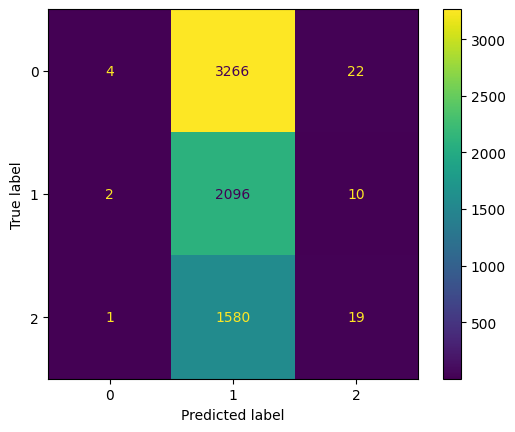

In [60]:
# Getting the ordinal (cumulative) logits from the output of the model (these are not probabilities or regular logits)
Y_test_ordinal_logits_1 = model_LSTM_cor_ord_1.predict(
    x={"Features_Input": X_num_test, "Industry_Input": X_embed_test})

# Converting from logits to label probabilities (this is initially a tensorflow tensor, and then converted to a np array)
Y_test_tensor_probs_1 = coral.ordinal_softmax(Y_test_ordinal_logits_1)
Y_test_probs_1 = Y_test_tensor_probs_1.numpy()

# Setting a threshold of predictions and getting the confusion matrix
threshold = 0.50
Y_test_co_1_pred_thresh = np.where(Y_test_probs_1[:, 0] > threshold, 0,
                             np.where(Y_test_probs_1[:, 2] > threshold, 2, 1))

# Getting the confusion matrix for the threshold
cf_thresh_co_1 = confusion_matrix(
    Y_test,
    Y_test_co_1_pred_thresh)
disp_co_1 = ConfusionMatrixDisplay(cf_thresh_co_1.astype(int))
disp_co_1.plot()
plt.show()

This is somewhat interesting - when using the ordinal regression method, the results are not outright terrible. Yes, the results aren't great either, but the numbers look more akin to what I had in my previous project. Furthermore, it's difficult to gauge anything without evaluating each individual test day, and I'll probably implement that next.

For clarity, I still want to try the linear activation function; however, what's more important beforehand is evaluating how well the model performs on individual test days (and not as a group). Because this current notebook is long enough as it is, I'll start a new notebook and implement my thoughts there.

In [62]:
# Fully flush out better way to evaluate model performance - you don't just need confusion matrices; you should have a function that does
# everything for you and gets you the precision metrics (and other metrics) that you had in your final 207 project.

In [64]:
# Basically for the above, turn EVERTHING you can into functions

In [63]:
# Also probably decrease training window size a bit so you have more test days

In [129]:
# Sample weights, class weights, sliding window, don't use validation, try linear regression instead of classification

In [28]:
# Might need to do a weight thing where incorrect predictions that were "more incorrect" pecentage-wise should be weighted more heavily
# Honestly, might we worth doing linear regression and seeing how off we are when it comes to our predictions
# Though then we run into the problem of outliers affecting our predictions too much; so, maybe cap how far it's wrong?
# ...KL Divergence maybe??... Ok, maybe not, it's just cross-entropy minus entropy lol